# Molecular property prediction with graph neural networks

### Blood–brain barrier penetration: fingerprint baselines, molecular graphs and scaffold-aware evaluation

**Scope.** This is an educational benchmark experiment. The BBBP label is a curated
literature annotation, not a clinical measurement. Nothing in this notebook
establishes that a compound is safe, effective, biologically causal, or ready for
drug development.

**What this notebook does, in one sentence:** it asks whether a bond-aware graph
neural network predicts blood–brain barrier penetration better than a 2015-vintage
molecular fingerprint with a linear model, and then asks how much of that answer
survives being tested on chemistry the model has never seen.

The notebook is self-contained: every function is defined in a cell below, and it
runs top to bottom after the environment is installed.

| § | Contents |
|---|---|
| **0** | Environment, configuration, metrics, fingerprints |
| **A** | Task definition and dataset inspection |
| **B** | Molecular graphs: features, batching, integrity checks |
| **C** | Random and Bemis–Murcko scaffold splits |
| **D** | Non-neural baseline: Morgan ECFP + logistic regression |
| **E** | The graph neural network: GINEConv, training, three seeds |
| **F** | Evaluation and the comparison of models and splits |
| **G** | Error analysis, similarity, and limitations |
| **H** | What the evidence supports |

---
## 0. Environment and configuration

Install once, then restart the kernel if asked:

```python
!pip -q install torch-geometric rdkit scikit-learn
```

**RDKit version matters.** This notebook pins `rdkit==2025.03.6`. In 2026.09.2,
`Chem.MurckoDecompose` raises `RuntimeError: bad any cast`, and a scaffold
extractor that catches that exception and returns an empty string will put *every*
molecule into one group — producing a scaffold split with an empty training set
that still passes every disjointness check. That failure is silent, so § C below
raises on it rather than catching it.

In [1]:
import copy, csv, json, sys, time
from dataclasses import dataclass, field, replace
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
from IPython.display import Image, display

import rdkit
from rdkit import Chem, RDLogger
RDLogger.DisableLog("rdApp.*")

print("python       ", sys.version.split()[0])
print("torch        ", torch.__version__)
import torch_geometric
print("torch_geometric", torch_geometric.__version__)
print("rdkit        ", rdkit.__version__)
import sklearn
print("scikit-learn ", sklearn.__version__)

python        3.12.7
torch         2.14.0


/opt/anaconda3/lib/python3.12/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


torch_geometric 2.8.1
rdkit         2025.03.6


scikit-learn  1.5.1


### 0.1 Every number that affects a result, in one place

Keeping the configuration in one object rather than scattered through the cells
means the run is reproducible from a single printed dictionary, and there is no
second copy of a hyperparameter to drift out of step.

In [2]:
from dataclasses import dataclass, field, asdict
from pathlib import Path

ROOT = Path.cwd()
DATA_ROOT = ROOT / "data" / "MoleculeNet"
RESULTS = ROOT / "results"
FIGURES = ROOT / "results" / "figures"

# The one seed that governs splitting. Model seeds are separate (see GNNConfig.seeds)
# so that "same split, different init" can be separated from "different split".
SPLIT_SEED = 0

TRAIN_FRAC = 0.70
VAL_FRAC = 0.15
TEST_FRAC = 0.15


@dataclass(frozen=True)
class FingerprintConfig:
    """Morgan / ECFP settings for the non-neural baseline and for similarity work."""

    radius: int = 2  # ECFP4: diameter 4 = radius 2
    n_bits: int = 2048
    use_chirality: bool = False


@dataclass(frozen=True)
class BaselineConfig:
    seed: int = 0
    # Searched on validation only.
    C_grid: tuple[float, ...] = (0.01, 0.03, 0.1, 0.3, 1.0, 3.0, 10.0)
    class_weight: str | None = "balanced"
    max_iter: int = 5000


@dataclass(frozen=True)
class GNNConfig:
    hidden: int = 128
    n_layers: int = 3
    dropout: float = 0.3
    pooling: str = "mean"  # mean | add | max | mean+max

    lr: float = 1e-3
    weight_decay: float = 1e-5
    batch_size: int = 64
    max_epochs: int = 200
    patience: int = 30  # early stopping on validation ROC-AUC

    seeds: tuple[int, ...] = (0, 1, 2)
    device: str = "auto"  # auto | cpu | mps | cuda


@dataclass(frozen=True)
class Config:
    fingerprint: FingerprintConfig = field(default_factory=FingerprintConfig)
    baseline: BaselineConfig = field(default_factory=BaselineConfig)
    gnn: GNNConfig = field(default_factory=GNNConfig)
    split_seed: int = SPLIT_SEED
    train_frac: float = TRAIN_FRAC
    val_frac: float = VAL_FRAC
    test_frac: float = TEST_FRAC

    def to_dict(self) -> dict:
        return asdict(self)


CONFIG = Config()


def resolve_device(requested: str = "auto") -> str:
    """Pick a torch device.

    Defaults to CPU. This dataset is tiny (~2k graphs of ~25 atoms), so CPU is
    fast and avoids the scatter-op edge cases that PyG still hits on MPS.
    """
    import torch

    if requested != "auto":
        return requested
    if torch.cuda.is_available():
        return "cuda"
    return "cpu"

In [3]:
print(json.dumps(CONFIG.to_dict(), indent=2))
print("\nsplit seed:", SPLIT_SEED, " device:", resolve_device())
RESULTS.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)
out = {"config": CONFIG.to_dict()}   # accumulates everything, written to JSON at the end

{
  "fingerprint": {
    "radius": 2,
    "n_bits": 2048,
    "use_chirality": false
  },
  "baseline": {
    "seed": 0,
    "C_grid": [
      0.01,
      0.03,
      0.1,
      0.3,
      1.0,
      3.0,
      10.0
    ],
    "class_weight": "balanced",
    "max_iter": 5000
  },
  "gnn": {
    "hidden": 128,
    "n_layers": 3,
    "dropout": 0.3,
    "pooling": "mean",
    "lr": 0.001,
    "weight_decay": 1e-05,
    "batch_size": 64,
    "max_epochs": 200,
    "patience": 30,
    "seeds": [
      0,
      1,
      2
    ],
    "device": "auto"
  },
  "split_seed": 0,
  "train_frac": 0.7,
  "val_frac": 0.15,
  "test_frac": 0.15
}

split seed: 0  device: cpu


### 0.2 Metrics

**Why balanced accuracy and specificity are reported alongside accuracy.** BBBP is
imbalanced in the *unusual* direction: about 76% of the molecules are positive. A
model that predicts "penetrates" for everything scores 0.76 accuracy and an F1
above 0.86 while being worthless. Balanced accuracy and specificity are the
columns that expose it, so they are computed here from the start rather than added
later.

The decision threshold is **selected on validation and frozen**. Choosing the
threshold that flatters the test set is fitting to the test set by hand.

In [4]:
import numpy as np
from sklearn.metrics import (
    average_precision_score,
    confusion_matrix,
    precision_recall_curve,
    roc_auc_score,
    roc_curve,
)


def classification_metrics(
    y_true: np.ndarray, y_prob: np.ndarray, threshold: float
) -> dict[str, float]:
    y_true = np.asarray(y_true).astype(int)
    y_prob = np.asarray(y_prob, dtype=float)
    y_pred = (y_prob >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    sensitivity = tp / (tp + fn) if (tp + fn) else float("nan")
    specificity = tn / (tn + fp) if (tn + fp) else float("nan")
    precision = tp / (tp + fp) if (tp + fp) else float("nan")
    f1 = (
        2 * precision * sensitivity / (precision + sensitivity)
        if precision + sensitivity > 0
        else 0.0
    )
    # Balanced accuracy is the honest headline number on an imbalanced set.
    balanced_acc = (sensitivity + specificity) / 2

    both_classes = len(np.unique(y_true)) > 1
    return {
        "threshold": float(threshold),
        "roc_auc": float(roc_auc_score(y_true, y_prob)) if both_classes else float("nan"),
        "pr_auc": float(average_precision_score(y_true, y_prob))
        if both_classes
        else float("nan"),
        "accuracy": float((y_pred == y_true).mean()),
        "balanced_accuracy": float(balanced_acc),
        "sensitivity": float(sensitivity),
        "specificity": float(specificity),
        "precision": float(precision),
        "f1": float(f1),
        "tn": int(tn),
        "fp": int(fp),
        "fn": int(fn),
        "tp": int(tp),
        "n": int(len(y_true)),
        "positive_frac": float(y_true.mean()),
    }


def select_threshold(
    y_true: np.ndarray, y_prob: np.ndarray, objective: str = "f1"
) -> float:
    """Choose a decision threshold on validation data.

    `f1` maximises F1. `youden` maximises sensitivity + specificity - 1, which
    treats the two error types symmetrically and is the better choice when the
    majority class dominates.
    """
    y_true = np.asarray(y_true).astype(int)
    y_prob = np.asarray(y_prob, dtype=float)

    if objective == "youden":
        fpr, tpr, thr = roc_curve(y_true, y_prob)
        j = tpr - fpr
        best = thr[int(np.argmax(j))]
        return float(np.clip(best, 0.0, 1.0))

    if objective == "f1":
        precision, recall, thr = precision_recall_curve(y_true, y_prob)
        # thr has one fewer entry than precision/recall
        f1 = np.divide(
            2 * precision[:-1] * recall[:-1],
            precision[:-1] + recall[:-1],
            out=np.zeros_like(thr),
            where=(precision[:-1] + recall[:-1]) > 0,
        )
        return float(thr[int(np.argmax(f1))])

    raise ValueError(f"unknown objective: {objective}")


def curves(y_true: np.ndarray, y_prob: np.ndarray) -> dict[str, np.ndarray]:
    fpr, tpr, _ = roc_curve(y_true, y_prob)
    precision, recall, _ = precision_recall_curve(y_true, y_prob)
    return {"fpr": fpr, "tpr": tpr, "precision": precision, "recall": recall}


def summarise_runs(rows: list[dict], keys: list[str] | None = None) -> dict[str, str]:
    """Mean +/- standard deviation over repeated runs, formatted for a table."""
    keys = keys or [
        "roc_auc",
        "pr_auc",
        "accuracy",
        "balanced_accuracy",
        "sensitivity",
        "specificity",
        "f1",
    ]
    out = {}
    for k in keys:
        vals = np.array([r[k] for r in rows], dtype=float)
        out[k] = f"{vals.mean():.3f} +/- {vals.std(ddof=1 if len(vals) > 1 else 0):.3f}"
    return out

### 0.3 Morgan / ECFP fingerprints and Tanimoto similarity

A Morgan fingerprint of radius 2 (ECFP4) hashes every circular atom
neighbourhood up to two bonds out into a 2048-bit vector: bit *i* is set if some
substructure hashing to *i* is present. It is a presence/absence description of
local chemistry, with no notion of global shape.

Tanimoto similarity between two such bit vectors is $|A \cap B| / |A \cup B|$.
This is used twice below — once for the baseline's features, once in § G to
measure how far a test molecule sits from anything the model was trained on.

In [5]:
import numpy as np



def _generator(cfg: FingerprintConfig):
    from rdkit.Chem import rdFingerprintGenerator

    return rdFingerprintGenerator.GetMorganGenerator(
        radius=cfg.radius,
        fpSize=cfg.n_bits,
        includeChirality=cfg.use_chirality,
    )


def fingerprint_objects(smiles: list[str], cfg: FingerprintConfig | None = None):
    """RDKit bit-vector objects, needed for fast Tanimoto comparisons."""
    from rdkit import Chem, RDLogger

    RDLogger.DisableLog("rdApp.*")
    cfg = cfg or FingerprintConfig()
    gen = _generator(cfg)
    out = []
    for s in smiles:
        mol = Chem.MolFromSmiles(s)
        if mol is None:
            raise ValueError(f"unparseable SMILES reached fingerprinting: {s!r}")
        out.append(gen.GetFingerprint(mol))
    return out


def fingerprint_matrix(
    smiles: list[str], cfg: FingerprintConfig | None = None
) -> np.ndarray:
    """Dense 0/1 matrix of shape (n_molecules, n_bits)."""
    from rdkit import DataStructs

    cfg = cfg or FingerprintConfig()
    fps = fingerprint_objects(smiles, cfg)
    arr = np.zeros((len(fps), cfg.n_bits), dtype=np.uint8)
    for i, fp in enumerate(fps):
        DataStructs.ConvertToNumpyArray(fp, arr[i])
    return arr


def tanimoto_to_reference(
    query_smiles: list[str],
    reference_smiles: list[str],
    cfg: FingerprintConfig | None = None,
) -> np.ndarray:
    """Full similarity matrix, shape (n_query, n_reference).

    Tanimoto similarity of two bit vectors is |A AND B| / |A OR B|: the share of
    all substructures present in either molecule that are present in both. 1.0
    means identical fingerprints, 0.0 means no shared substructure.
    """
    from rdkit import DataStructs

    cfg = cfg or FingerprintConfig()
    q = fingerprint_objects(query_smiles, cfg)
    r = fingerprint_objects(reference_smiles, cfg)
    sims = np.zeros((len(q), len(r)), dtype=np.float32)
    for i, fp in enumerate(q):
        sims[i] = DataStructs.BulkTanimotoSimilarity(fp, r)
    return sims


def nearest_training_neighbour(
    query_smiles: list[str],
    train_smiles: list[str],
    cfg: FingerprintConfig | None = None,
) -> tuple[np.ndarray, np.ndarray]:
    """For each query molecule, the most similar training molecule.

    Returns (similarity, index_into_train). This is the quantity that defines an
    applicability domain: a test molecule far from everything in training is one
    the model has no business being confident about.
    """
    sims = tanimoto_to_reference(query_smiles, train_smiles, cfg)
    best_idx = sims.argmax(axis=1)
    best_sim = sims[np.arange(len(query_smiles)), best_idx]
    return best_sim, best_idx

---
# A. Task definition and dataset inspection

### A.1 Input, output, unit of analysis, intended use

| | |
|---|---|
| **Input** | one molecule, as a SMILES string, converted to a graph: atoms are nodes, bonds are edges |
| **Output** | one probability in $[0,1]$ for the whole molecule |
| **Unit of analysis** | the molecule. Not an atom, not a patient, not a dose |
| **Task type** | graph-level binary classification |
| **Intended technical use** | ranking and triage in a method-comparison experiment |

**What the labels mean.** `p_np = 1` means the compound is annotated in the source
literature as penetrating the blood–brain barrier; `p_np = 0` means annotated as
non-penetrating. These are curated research annotations compiled by Martins et al.
(2012) from heterogeneous sources — different assays, different species,
different definitions of "penetrating". They are not measurements taken under one
protocol, and § G returns to what that implies.

**Not an intended use:** deciding whether a compound is safe, whether it should be
synthesised, or anything about a patient.

### A.2 Loading, canonicalization, and the cleaning rule

One SMILES string is not one molecule. The same compound can be written many
ways, so de-duplicating on the raw string finds only some of the repeats. Every
SMILES is therefore canonicalized with RDKit first, and duplicates are found on
the canonical form.

The cleaning rule, applied **before any split is made**:

1. Drop molecules RDKit cannot parse, molecules with no atoms, and non-finite labels.
2. Canonicalize every remaining SMILES.
3. Where several records share a canonical SMILES **and agree** on the label, keep one.
4. Where several records share a canonical SMILES and **disagree** on the label,
   delete the entire group and report it.

Rule 4 costs molecules, but it is the only defensible option. Keeping either label
guarantees a known-wrong example somewhere in training or test, and if it lands in
test it makes a correct prediction score as an error.

This is not a hypothetical: **BBBP contains aspirin twice, under two spellings,
with opposite labels** — record 102 (`acetylsalicylate`, `p_np=0`) and record 1009
(`aspirin`, `p_np=1`).

In [6]:
import warnings
from collections import defaultdict
from dataclasses import dataclass
from pathlib import Path

import torch
from torch_geometric.data import Data
from torch_geometric.datasets import MoleculeNet


warnings.filterwarnings("ignore", category=FutureWarning)

# Column meanings for the PyG `from_smiles` featurization, in order.
# Source: torch_geometric.utils.smiles (x_map / e_map).
ATOM_FEATURES = [
    ("atomic_num", 119),
    ("chirality", 4),
    ("degree", 11),
    ("formal_charge", 12),
    ("num_hs", 9),
    ("num_radical_electrons", 5),
    ("hybridization", 8),
    ("is_aromatic", 2),
    ("is_in_ring", 2),
]
BOND_FEATURES = [
    ("bond_type", 22),
    ("stereo", 6),
    ("is_conjugated", 2),
]

ATOM_DIMS = [n for _, n in ATOM_FEATURES]
BOND_DIMS = [n for _, n in BOND_FEATURES]


@dataclass
class CleaningReport:
    """Everything that was dropped, and why. Printed and saved as JSON."""

    n_raw_csv: int | None
    n_loaded: int
    n_unparseable: int
    n_empty_graph: int
    n_bad_label: int
    n_duplicate_records_removed: int
    n_conflict_groups: int
    n_conflict_records_removed: int
    n_clean: int
    conflict_examples: list[dict]
    duplicate_examples: list[dict]

    def summary(self) -> str:
        lines = [
            f"raw CSV rows                     {self.n_raw_csv}",
            f"graphs built by PyG              {self.n_loaded}",
            f"  dropped, unparseable SMILES    {self.n_unparseable}",
            f"  dropped, empty graph           {self.n_empty_graph}",
            f"  dropped, missing/non-finite y  {self.n_bad_label}",
            f"  dropped, duplicate records     {self.n_duplicate_records_removed}",
            f"  dropped, conflicting labels    {self.n_conflict_records_removed}"
            f" (in {self.n_conflict_groups} groups)",
            f"clean molecules                  {self.n_clean}",
        ]
        return "\n".join(lines)


def canonical_smiles(smiles: str, include_stereo: bool = True) -> str | None:
    """Canonical SMILES, or None if RDKit cannot parse the string."""
    from rdkit import Chem, RDLogger

    RDLogger.DisableLog("rdApp.*")
    mol = Chem.MolFromSmiles(smiles)
    if mol is None or mol.GetNumAtoms() == 0:
        return None
    return Chem.MolToSmiles(mol, isomericSmiles=include_stereo)


def _raw_csv_rows() -> int | None:
    """Row count of the file PyG downloaded, so we can see what PyG itself dropped."""
    candidates = list(Path(DATA_ROOT).rglob("BBBP.csv"))
    if not candidates:
        return None
    import csv

    with open(candidates[0], newline="", encoding="utf-8", errors="replace") as fh:
        return sum(1 for _ in csv.reader(fh)) - 1  # minus header


def load_raw(root: Path | str = DATA_ROOT) -> MoleculeNet:
    return MoleculeNet(root=str(root), name="BBBP")


def clean_dataset(
    dataset: MoleculeNet | None = None,
    include_stereo: bool = True,
) -> tuple[list[Data], CleaningReport]:
    """Return the cleaned list of graphs plus a report of everything removed.

    Each returned graph gains `.canonical_smiles` and a scalar `.label`.
    """
    if dataset is None:
        dataset = load_raw()

    n_unparseable = n_empty = n_bad_label = 0
    by_canonical: dict[str, list[Data]] = defaultdict(list)

    for data in dataset:
        if data.x is None or data.num_nodes == 0 or data.x.numel() == 0:
            n_empty += 1
            continue
        y = float(data.y.view(-1)[0])
        if y != y or y in (float("inf"), float("-inf")):  # NaN or inf
            n_bad_label += 1
            continue
        canon = canonical_smiles(data.smiles, include_stereo=include_stereo)
        if canon is None:
            n_unparseable += 1
            continue
        data.canonical_smiles = canon
        data.label = y
        by_canonical[canon].append(data)

    clean: list[Data] = []
    n_dupe_removed = 0
    conflict_groups = 0
    n_conflict_removed = 0
    conflict_examples: list[dict] = []
    duplicate_examples: list[dict] = []

    for canon, group in by_canonical.items():
        labels = {d.label for d in group}
        if len(labels) > 1:
            conflict_groups += 1
            n_conflict_removed += len(group)
            if len(conflict_examples) < 10:
                conflict_examples.append(
                    {
                        "canonical_smiles": canon,
                        "n_records": len(group),
                        "labels": sorted(labels),
                        "original_smiles": [d.smiles for d in group],
                    }
                )
            continue
        if len(group) > 1:
            n_dupe_removed += len(group) - 1
            if len(duplicate_examples) < 10:
                duplicate_examples.append(
                    {
                        "canonical_smiles": canon,
                        "n_records": len(group),
                        "label": group[0].label,
                        "original_smiles": [d.smiles for d in group],
                    }
                )
        clean.append(group[0])

    # Stable order so that an index means the same molecule on every run.
    clean.sort(key=lambda d: d.canonical_smiles)
    for i, d in enumerate(clean):
        d.idx = i

    report = CleaningReport(
        n_raw_csv=_raw_csv_rows(),
        n_loaded=len(dataset),
        n_unparseable=n_unparseable,
        n_empty_graph=n_empty,
        n_bad_label=n_bad_label,
        n_duplicate_records_removed=n_dupe_removed,
        n_conflict_groups=conflict_groups,
        n_conflict_records_removed=n_conflict_removed,
        n_clean=len(clean),
        conflict_examples=conflict_examples,
        duplicate_examples=duplicate_examples,
    )
    return clean, report


def labels_tensor(graphs: list[Data]) -> torch.Tensor:
    return torch.tensor([g.label for g in graphs], dtype=torch.float)


def smiles_list(graphs: list[Data]) -> list[str]:
    return [g.canonical_smiles for g in graphs]


def integrity_checks(graphs: list[Data]) -> dict[str, bool]:
    """Assertions the pipeline must satisfy before any model sees the data."""
    ys = labels_tensor(graphs)
    checks = {
        "all labels finite": bool(torch.isfinite(ys).all()),
        "all labels binary": bool(((ys == 0) | (ys == 1)).all()),
        "every graph has >=1 atom": all(g.num_nodes >= 1 for g in graphs),
        "every graph has edge_attr rows == edges": all(
            g.edge_attr.shape[0] == g.edge_index.shape[1] for g in graphs
        ),
        "atom feature columns == 9": all(g.x.shape[1] == len(ATOM_DIMS) for g in graphs),
        "bond feature columns == 3": all(
            g.edge_attr.shape[1] == len(BOND_DIMS) for g in graphs
        ),
        "canonical SMILES unique": len({g.canonical_smiles for g in graphs})
        == len(graphs),
        "atom codes within vocabulary": all(
            bool((g.x[:, c] < ATOM_DIMS[c]).all()) for g in graphs for c in range(9)
        ),
        "bond codes within vocabulary": all(
            bool((g.edge_attr[:, c] < BOND_DIMS[c]).all())
            for g in graphs
            if g.edge_attr.numel()
            for c in range(3)
        ),
    }
    return checks

In [7]:
raw = load_raw()
print(raw)
print("raw molecules:", len(raw))
print("first graph:", raw[0])

BBBP(2039)
raw molecules: 2039
first graph: Data(x=[20, 9], edge_index=[2, 40], edge_attr=[40, 3], smiles='[Cl].CC(C)NCC(O)COc1cccc2ccccc12', y=[1, 1])


In [8]:
graphs, report = clean_dataset(raw)
print(report.summary())

y = labels_tensor(graphs).numpy()
smiles = smiles_list(graphs)
print(f"\nclass counts:        negative {int((y == 0).sum())}, positive {int((y == 1).sum())}")
print(f"positive proportion: {y.mean():.4f}")
print(f"negative proportion: {1 - y.mean():.4f}")
out["cleaning"] = dict(report.__dict__)

raw CSV rows                     2050
graphs built by PyG              2039
  dropped, unparseable SMILES    0
  dropped, empty graph           0
  dropped, missing/non-finite y  0
  dropped, duplicate records     54
  dropped, conflicting labels    20 (in 10 groups)
clean molecules                  1965

class counts:        negative 465, positive 1500
positive proportion: 0.7634
negative proportion: 0.2366


In [9]:
print("conflicting-label groups removed (every one is a molecule appearing with BOTH labels):")
for ex in report.conflict_examples[:10]:
    print(f"  {ex['canonical_smiles']}")
    print(f"      labels={ex['labels']}  written as {ex['original_smiles']}")

print(f"\nduplicate structures collapsed to one record (first 10 of {report.n_duplicate_records_removed}):")
for ex in report.duplicate_examples[:10]:
    print(f"  {ex['canonical_smiles']}  x{ex['n_records']}")
    print(f"      written as {ex['original_smiles']}")

conflicting-label groups removed (every one is a molecule appearing with BOTH labels):
  CN(C)C(=O)C(CCN1CCC(O)(c2ccc(Cl)cc2)CC1)(c1ccccc1)c1ccccc1
      labels=[0.0, 1.0]  written as ['CN(C)C(=O)C(CCN1CCC(O)(CC1)c1ccc(Cl)cc1)(c1ccccc1)c1ccccc1', 'CN(C)C(=O)C(CCN1CCC(O)(CC1)c2ccc(Cl)cc2)(c3ccccc3)c4ccccc4']
  CC(=O)Oc1ccccc1C(=O)O
      labels=[0.0, 1.0]  written as ['CC(=O)Oc1ccccc1C(O)=O', 'C1=CC=CC(=C1C(O)=O)OC(C)=O']
  CN1C2CCC1CC(OC(=O)C(CO)c1ccccc1)C2
      labels=[0.0, 1.0]  written as ['CN1C2CCC1CC(C2)OC(=O)C(CO)c3ccccc3', 'C1=CC=CC=C1C(C(OC2CC3N(C)C(C2)CC3)=O)CO']
  COc1cc(NCc2ccc3nc(N)nc(N)c3c2C)cc(OC)c1OC
      labels=[0.0, 1.0]  written as ['COc1cc(NCc2ccc3nc(N)nc(N)c3c2C)cc(OC)c1OC', 'C1=C3C(=C(C(=C1)CNC2=CC(=C(C(=C2)OC)OC)OC)C)C(=NC(=N3)N)N']
  COc1ccc2c(c1)c(CC(=O)O)c(C)n2C(=O)c1ccc(Cl)cc1
      labels=[0.0, 1.0]  written as ['COc1ccc2n(c(C)c(CC(O)=O)c2c1)C(=O)c3ccc(Cl)cc3', 'C1=CC(=CC2=C1[N](C(=C2CC(O)=O)C)C(C3=CC=C(Cl)C=C3)=O)OC']
  N[C@@H](Cc1ccc(O)c(O)c1)C(=O)O
     

#### What the source CSV's own `name` column says about the conflicts

The cleaning rule above works purely on structure. The raw MoleculeNet file also carries a
`name` field, which was not used for anything in the pipeline — but reading it back for the
ten conflicting groups shows *how* the contradiction got there.

In [10]:
import csv, collections
raw_csv = next(Path("data").rglob("BBBP.csv"))
rows = list(csv.DictReader(open(raw_csv)))
by_can = collections.defaultdict(list)
for r in rows:
    m = Chem.MolFromSmiles(r["smiles"])
    if m is not None:
        by_can[Chem.MolToSmiles(m)].append((r["name"], r["p_np"], r["smiles"]))

n = 0
for can, recs in by_can.items():
    if len({x[1] for x in recs}) > 1:
        n += 1
        same_string = len({x[2] for x in recs}) == 1
        print(f"{n:2d}. {' / '.join(x[0] for x in recs)}")
        print(f"     labels {[x[1] for x in recs]}   "
              f"same SMILES string: {same_string}")
print(f"\n{n} conflicting groups. Detectable without canonicalization: "
      f"{sum(1 for can, recs in by_can.items() if len({x[1] for x in recs}) > 1 and len({x[2] for x in recs}) == 1)}")

 1. BRL53080 / loperamide
     labels ['1', '0']   same SMILES string: False
 2. acetylsalicylate / aspirin
     labels ['0', '1']   same SMILES string: False
 3. atropine / atropine(hyoscyamine)
     labels ['0', '1']   same SMILES string: False
 4. Trimetrexate / trimetrexate
     labels ['0', '1']   same SMILES string: False
 5. indomethacin / indomethacin(indometacin)
     labels ['0', '1']   same SMILES string: False
 6. levodopa / levodopa
     labels ['0', '1']   same SMILES string: False
 7. mequitazine / mequitazine
     labels ['0', '1']   same SMILES string: False
 8. Methylprednisolone / methylprednisolone
     labels ['0', '1']   same SMILES string: False
 9. Miconazole / miconazole
     labels ['0', '1']   same SMILES string: False
10. loratadine / loratadine
     labels ['0', '1']   same SMILES string: False

10 conflicting groups. Detectable without canonicalization: 0


### A.3 Six molecules, both classes

In [11]:
pos = [i for i in range(len(graphs)) if y[i] == 1][:3]
neg = [i for i in range(len(graphs)) if y[i] == 0][:3]
pick = pos + neg
for i in pick:
    print(f"  y={int(y[i])}  {'penetrates    ' if y[i] else 'does not penetrate'}  {smiles[i]}")

  y=1  penetrates      BrC(Br)Br
  y=1  penetrates      C#CC(C)(O)CC
  y=1  penetrates      C#CC(O)(/C=C/Cl)CC
  y=0  does not penetrate  C#C[C@]1(O)CC[C@H]2[C@@H]3CCC4=CC(=O)CC[C@@H]4[C@H]3CC[C@@]21C
  y=0  does not penetrate  C#C[C@]1(O)CC[C@H]2[C@@H]3CCc4cc(O)ccc4[C@H]3CC[C@@]21C
  y=0  does not penetrate  C#C[C@]1(O)CC[C@H]2[C@@H]3CCc4cc(OC)ccc4[C@H]3CC[C@@]21C


### A.4 Graph size distributions and one graph inspected

In [12]:
from pathlib import Path

import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np


# A small fixed palette, assigned in order and never cycled.
COLORS = {
    "fingerprint": "#3B6FB6",   # blue
    "gnn": "#C8613A",           # warm orange
    "random": "#3B6FB6",
    "scaffold": "#C8613A",
    "chance": "#9AA0A6",
    "grid": "#D9DCE0",
}


def _setup(ax, xlabel: str, ylabel: str, title: str) -> None:
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_title(title, loc="left", fontsize=11)
    ax.grid(True, color=COLORS["grid"], linewidth=0.6)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)


def _save(fig, name: str) -> Path:
    FIGURES.mkdir(parents=True, exist_ok=True)
    path = FIGURES / name
    fig.tight_layout()
    fig.savefig(path, dpi=160, bbox_inches="tight")
    plt.close(fig)
    return path


def training_curves(history, name: str, title: str) -> Path:
    fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
    epochs = np.arange(len(history.train_loss))

    axes[0].plot(epochs, history.train_loss, color=COLORS["fingerprint"], lw=2,
                 label="train")
    axes[0].plot(epochs, history.val_loss, color=COLORS["gnn"], lw=2,
                 label="validation")
    axes[0].axvline(history.best_epoch, color=COLORS["chance"], ls="--", lw=1.2)
    _setup(axes[0], "epoch", "BCE loss", "Loss")
    axes[0].legend(frameon=False)

    axes[1].plot(epochs, history.val_roc_auc, color=COLORS["gnn"], lw=2)
    axes[1].axvline(history.best_epoch, color=COLORS["chance"], ls="--", lw=1.2)
    axes[1].annotate(
        f"best epoch {history.best_epoch}",
        xy=(history.best_epoch, history.val_roc_auc[history.best_epoch]),
        xytext=(6, -14),
        textcoords="offset points",
        fontsize=9,
        color="#444",
    )
    _setup(axes[1], "epoch", "validation ROC-AUC", "Validation ranking quality")

    fig.suptitle(title, x=0.01, ha="left", fontsize=12)
    return _save(fig, name)


def roc_pr_curves(results: dict[str, dict], name: str, title: str) -> Path:
    """results: {label: {"y": ..., "prob": ..., "color_key": ...}}"""
    fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))

    for label, r in results.items():
        c = COLORS.get(r.get("color_key", ""), COLORS["fingerprint"])
        cur = curves(r["y"], r["prob"])
        from sklearn.metrics import average_precision_score, roc_auc_score

        auc = roc_auc_score(r["y"], r["prob"])
        ap = average_precision_score(r["y"], r["prob"])
        axes[0].plot(cur["fpr"], cur["tpr"], lw=2, color=c, label=f"{label} ({auc:.3f})")
        axes[1].plot(
            cur["recall"], cur["precision"], lw=2, color=c, label=f"{label} ({ap:.3f})"
        )

    axes[0].plot([0, 1], [0, 1], ls="--", lw=1.2, color=COLORS["chance"])
    _setup(axes[0], "false positive rate", "true positive rate", "ROC")
    axes[0].legend(frameon=False, fontsize=9, loc="lower right")

    any_r = next(iter(results.values()))
    base = float(np.mean(any_r["y"]))
    axes[1].axhline(base, ls="--", lw=1.2, color=COLORS["chance"])
    axes[1].annotate(
        f"base rate {base:.2f}",
        xy=(0.02, base),
        xytext=(0, 5),
        textcoords="offset points",
        fontsize=9,
        color="#444",
    )
    _setup(axes[1], "recall", "precision", "Precision-recall")
    axes[1].legend(frameon=False, fontsize=9, loc="lower left")

    fig.suptitle(title, x=0.01, ha="left", fontsize=12)
    return _save(fig, name)


def confusion_matrices(panels: list[dict], name: str, title: str) -> Path:
    """panels: [{"label": str, "metrics": dict}]"""
    n = len(panels)
    fig, axes = plt.subplots(1, n, figsize=(3.0 * n, 3.1))
    if n == 1:
        axes = [axes]

    for ax, p in zip(axes, panels):
        m = p["metrics"]
        cm = np.array([[m["tn"], m["fp"]], [m["fn"], m["tp"]]], dtype=float)
        norm = cm / cm.sum(axis=1, keepdims=True).clip(min=1)
        ax.imshow(norm, cmap="Blues", vmin=0, vmax=1)
        for i in range(2):
            for j in range(2):
                ax.text(
                    j, i, f"{int(cm[i, j])}\n{norm[i, j]:.0%}",
                    ha="center", va="center", fontsize=10,
                    color="white" if norm[i, j] > 0.55 else "#222",
                )
        ax.set_xticks([0, 1], ["pred 0", "pred 1"])
        ax.set_yticks([0, 1], ["true 0", "true 1"])
        ax.set_title(f"{p['label']}\nthr {m['threshold']:.2f}", fontsize=10, loc="left")
        ax.grid(False)

    fig.suptitle(title, x=0.01, ha="left", fontsize=12)
    return _save(fig, name)


def count_distributions(atom_counts, bond_counts, name: str) -> Path:
    fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
    for ax, vals, label in (
        (axes[0], atom_counts, "atoms per molecule"),
        (axes[1], bond_counts, "bonds per molecule"),
    ):
        ax.hist(vals, bins=40, color=COLORS["fingerprint"], edgecolor="white", lw=0.4)
        med = float(np.median(vals))
        ax.axvline(med, color=COLORS["gnn"], lw=1.6)
        ax.annotate(
            f"median {med:.0f}", xy=(med, ax.get_ylim()[1] * 0.9),
            xytext=(6, 0), textcoords="offset points", fontsize=9, color="#444",
        )
        _setup(ax, label, "molecules", label.capitalize())
    fig.suptitle("Graph size distribution", x=0.01, ha="left", fontsize=12)
    return _save(fig, name)


def similarity_vs_correctness(sims, correct, name: str, title: str) -> Path:
    """Does nearest-training similarity predict whether the model is right?"""
    sims = np.asarray(sims, dtype=float)
    correct = np.asarray(correct).astype(bool)
    edges = np.linspace(sims.min(), sims.max(), 7)
    centres, acc, counts = [], [], []
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (sims >= lo) & (sims < hi if hi < edges[-1] else sims <= hi)
        if m.sum() >= 5:
            centres.append((lo + hi) / 2)
            acc.append(correct[m].mean())
            counts.append(int(m.sum()))

    fig, ax = plt.subplots(figsize=(6, 3.6))
    ax.plot(centres, acc, "-o", color=COLORS["gnn"], lw=2, ms=7)
    for x, y, c in zip(centres, acc, counts):
        ax.annotate(f"n={c}", xy=(x, y), xytext=(0, 8), textcoords="offset points",
                    ha="center", fontsize=8, color="#666")
    ax.axhline(correct.mean(), ls="--", lw=1.2, color=COLORS["chance"])
    ax.annotate(
        f"overall {correct.mean():.0%}",
        xy=(centres[-1], correct.mean()),
        xytext=(4, -13),
        textcoords="offset points",
        ha="right",
        fontsize=9,
        color="#444",
    )
    ax.set_ylim(0.0, 1.12)
    _setup(ax, "Tanimoto similarity to nearest training molecule",
           "fraction predicted correctly", title)
    return _save(fig, name)


def molecule_grid(smiles: list[str], legends: list[str], name: str,
                  mols_per_row: int = 3) -> Path:
    from rdkit import Chem, RDLogger
    from rdkit.Chem import Draw

    RDLogger.DisableLog("rdApp.*")
    mols = [Chem.MolFromSmiles(s) for s in smiles]
    img = Draw.MolsToGridImage(
        mols, molsPerRow=mols_per_row, subImgSize=(320, 260), legends=legends
    )
    FIGURES.mkdir(parents=True, exist_ok=True)
    path = FIGURES / name
    data = img.data if hasattr(img, "data") else img
    if isinstance(data, bytes):
        path.write_bytes(data)
    else:  # PIL image
        img.save(path)
    return path


def molecule_as_graph(smiles: str, name: str) -> Path:
    """The same molecule drawn as chemistry and as a node-edge graph."""
    from rdkit import Chem, RDLogger
    from rdkit.Chem import Draw
    from rdkit.Chem.Draw import rdMolDraw2D
    import io
    from PIL import Image

    RDLogger.DisableLog("rdApp.*")
    mol = Chem.MolFromSmiles(smiles)

    drawer = rdMolDraw2D.MolDraw2DCairo(440, 380)
    opts = drawer.drawOptions()
    opts.addAtomIndices = True
    rdMolDraw2D.PrepareAndDrawMolecule(drawer, mol)
    drawer.FinishDrawing()
    chem_img = Image.open(io.BytesIO(drawer.GetDrawingText()))

    fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
    axes[0].imshow(chem_img)
    axes[0].axis("off")
    axes[0].set_title("Chemical structure (atom indices shown)", fontsize=10, loc="left")

    from rdkit.Chem import rdDepictor

    rdDepictor.Compute2DCoords(mol)
    conf = mol.GetConformer()
    pos = {a.GetIdx(): (conf.GetAtomPosition(a.GetIdx()).x,
                        conf.GetAtomPosition(a.GetIdx()).y) for a in mol.GetAtoms()}

    ax = axes[1]
    bond_style = {
        Chem.BondType.SINGLE: (1.4, "-"),
        Chem.BondType.DOUBLE: (2.6, "-"),
        Chem.BondType.TRIPLE: (3.6, "-"),
        Chem.BondType.AROMATIC: (2.0, "--"),
    }
    for bond in mol.GetBonds():
        i, j = bond.GetBeginAtomIdx(), bond.GetEndAtomIdx()
        lw, ls = bond_style.get(bond.GetBondType(), (1.4, "-"))
        ax.plot([pos[i][0], pos[j][0]], [pos[i][1], pos[j][1]],
                color="#888", lw=lw, ls=ls, zorder=1)
    xs = [p[0] for p in pos.values()]
    ys = [p[1] for p in pos.values()]
    ax.scatter(xs, ys, s=560, c=COLORS["fingerprint"], zorder=2, edgecolors="white",
               linewidths=1.5)
    for a in mol.GetAtoms():
        x, y = pos[a.GetIdx()]
        ax.text(x, y, f"{a.GetIdx()}\n{a.GetSymbol()}", ha="center", va="center",
                fontsize=7.5, color="white", zorder=3, linespacing=0.9)
    ax.set_aspect("equal")
    ax.axis("off")
    ax.set_title("Node-edge graph (node label = index, element)", fontsize=10, loc="left")

    fig.suptitle(f"One molecule, two views: {smiles}", x=0.01, ha="left", fontsize=11)
    return _save(fig, name)

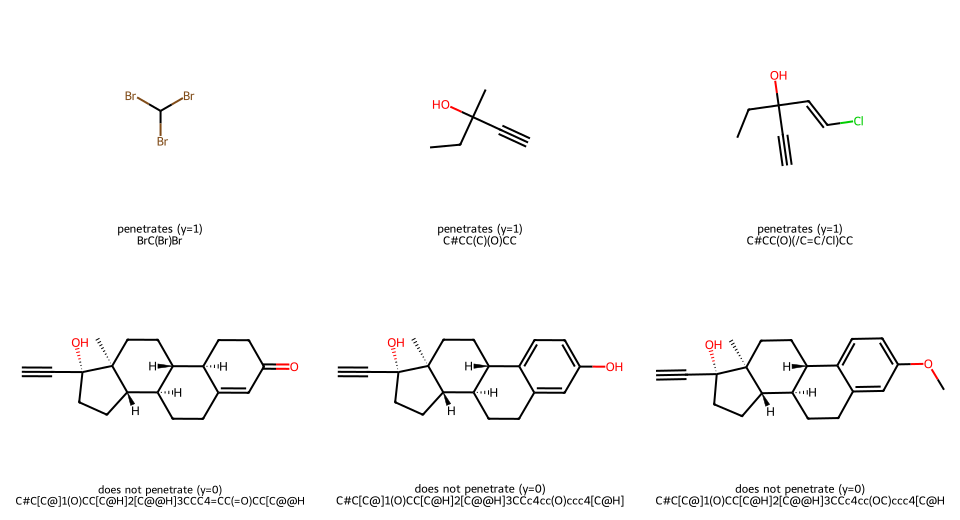

In [13]:
path = molecule_grid(
    [smiles[i] for i in pick],
    [f"{'penetrates' if y[i] else 'does not penetrate'} (y={int(y[i])})\n{smiles[i][:44]}"
     for i in pick],
    "02_example_molecules.png",
)
display(Image(str(path)))

atoms per molecule: min 2, median 23, mean 24.2, max 132
bonds per molecule: min 1, median 25, mean 26.1, max 145


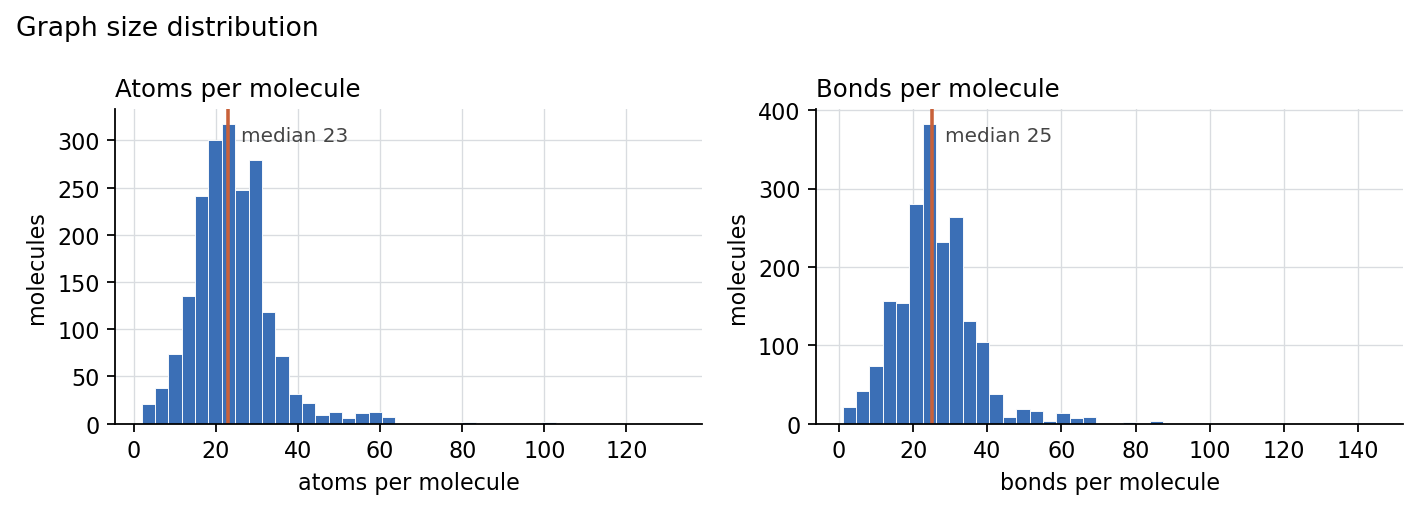

In [14]:
atom_counts = np.array([g.num_nodes for g in graphs])
bond_counts = np.array([g.edge_index.shape[1] // 2 for g in graphs])

print(f"atoms per molecule: min {atom_counts.min()}, median {np.median(atom_counts):.0f}, "
      f"mean {atom_counts.mean():.1f}, max {atom_counts.max()}")
print(f"bonds per molecule: min {bond_counts.min()}, median {np.median(bond_counts):.0f}, "
      f"mean {bond_counts.mean():.1f}, max {bond_counts.max()}")

out["graph_sizes"] = {
    "atoms": {"min": int(atom_counts.min()), "median": float(np.median(atom_counts)),
              "mean": float(atom_counts.mean()), "max": int(atom_counts.max())},
    "bonds": {"min": int(bond_counts.min()), "median": float(np.median(bond_counts)),
              "mean": float(bond_counts.mean()), "max": int(bond_counts.max())},
}
display(Image(str(count_distributions(atom_counts, bond_counts, "01_graph_sizes.png"))))

In [15]:
g0 = graphs[0]
print("example graph (index 0)")
print(f"  x.shape          {tuple(g0.x.shape)}    (n_atoms, 9 categorical atom features)")
print(f"  edge_index.shape {tuple(g0.edge_index.shape)}    (2, n_directed_edges)")
print(f"  edge_attr.shape  {tuple(g0.edge_attr.shape)}    (n_directed_edges, 3 bond features)")
print(f"  y                {float(g0.label)}")
print(f"  smiles           {g0.canonical_smiles}")
out["example_graph"] = {
    "x_shape": list(g0.x.shape), "edge_index_shape": list(g0.edge_index.shape),
    "edge_attr_shape": list(g0.edge_attr.shape),
    "y": float(g0.label), "smiles": g0.canonical_smiles,
}

example graph (index 0)
  x.shape          (4, 9)    (n_atoms, 9 categorical atom features)
  edge_index.shape (2, 6)    (2, n_directed_edges)
  edge_attr.shape  (6, 3)    (n_directed_edges, 3 bond features)
  y                1.0
  smiles           BrC(Br)Br


---
# B. Molecular graphs: features, batching, integrity

### B.1 What is in `x` and `edge_attr`, and why the codes are not numbers

PyTorch Geometric's `from_smiles` produces 9 atom columns and 3 bond columns.
**Every one is a category code.** Column 0 holds the atomic number, so carbon is 6
and lithium is 3 — but carbon is not "twice" lithium. Feeding those integers to a
linear layer asserts an ordering and a spacing that do not exist in chemistry.

**Encoding used here: trainable embeddings**, one `nn.Embedding` table per column,
summed to give the atom (or bond) vector. This is the OGB convention. It is
preferred over one-hot here because the atomic-number vocabulary alone is 119
wide, most of it never observed, and an embedding table learns a representation
only for the elements that actually occur.

In [16]:
print("atom feature columns  (x), each with its own embedding table:")
for i, (nm, dim) in enumerate(ATOM_FEATURES):
    print(f"  x[:, {i}]         {nm:26s} vocabulary {dim}")
print("\nbond feature columns  (edge_attr):")
for i, (nm, dim) in enumerate(BOND_FEATURES):
    print(f"  edge_attr[:, {i}]  {nm:26s} vocabulary {dim}")

atom feature columns  (x), each with its own embedding table:
  x[:, 0]         atomic_num                 vocabulary 119
  x[:, 1]         chirality                  vocabulary 4
  x[:, 2]         degree                     vocabulary 11
  x[:, 3]         formal_charge              vocabulary 12
  x[:, 4]         num_hs                     vocabulary 9
  x[:, 5]         num_radical_electrons      vocabulary 5
  x[:, 6]         hybridization              vocabulary 8
  x[:, 7]         is_aromatic                vocabulary 2
  x[:, 8]         is_in_ring                 vocabulary 2

bond feature columns  (edge_attr):
  edge_attr[:, 0]  bond_type                  vocabulary 22
  edge_attr[:, 1]  stereo                     vocabulary 6
  edge_attr[:, 2]  is_conjugated              vocabulary 2


### B.2 The same molecule as chemistry and as a node–edge graph

Each heavy atom in the drawing is one node, carrying the same index. Each bond in
the drawing is one edge — stored **twice** in `edge_index`, once in each
direction, because message passing has to send information both ways. Hydrogens
are implicit and are not nodes. Aromatic rings are drawn dashed on the right: the
ring is a cycle of nodes, and aromaticity lives in the bond's category code rather
than in the geometry.

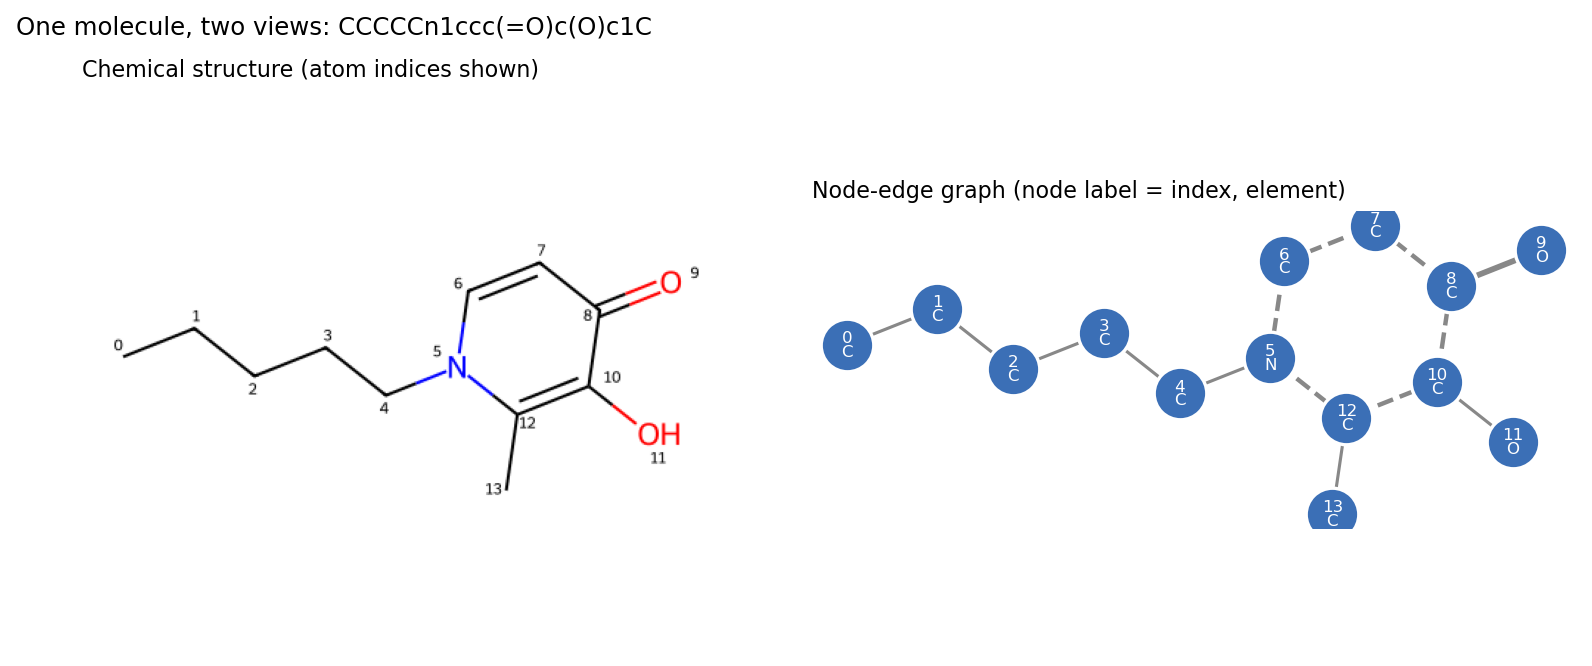

In [17]:
mid = int(np.argsort(np.abs(atom_counts - 14))[0])
display(Image(str(molecule_as_graph(smiles[mid], "03_molecule_two_views.png"))))

### B.3 Batching, and the checks that it lost nothing

PyG batches graphs by stacking them into one big disconnected graph. `x` becomes
every atom in the batch; `edge_index` indexes into that stack; `batch` records
which molecule each atom came from, which is what lets pooling produce one vector
per molecule rather than one per batch.

In [18]:
checks = integrity_checks(graphs)
for k, v in checks.items():
    print(f"  [{'ok' if v else 'FAIL'}] {k}")
assert all(checks.values()), "integrity checks failed"
out["integrity_checks"] = checks

  [ok] all labels finite
  [ok] all labels binary
  [ok] every graph has >=1 atom
  [ok] every graph has edge_attr rows == edges
  [ok] atom feature columns == 9
  [ok] bond feature columns == 3
  [ok] canonical SMILES unique
  [ok] atom codes within vocabulary
  [ok] bond codes within vocabulary


In [19]:
from torch_geometric.loader import DataLoader

b = next(iter(DataLoader(graphs[:128], batch_size=32, shuffle=False)))
print("one batch of 32 molecules:")
print(f"  x          {tuple(b.x.shape)}    every atom in the batch, stacked")
print(f"  edge_index {tuple(b.edge_index.shape)}    indices into the stacked atoms")
print(f"  edge_attr  {tuple(b.edge_attr.shape)}    one row per directed edge")
print(f"  batch      {tuple(b.batch.shape)}    which molecule each atom belongs to")
print(f"  y          {tuple(b.y.shape)}    one label per molecule")

assert b.y.view(-1).shape[0] == b.num_graphs == 32
assert int(b.batch.max()) + 1 == 32
assert b.edge_index.max() < b.x.shape[0]
print("\n  [ok] labels match graph count; no molecule lost in batching; edges stay in range")
out["example_batch"] = {"x": list(b.x.shape), "edge_index": list(b.edge_index.shape),
                        "edge_attr": list(b.edge_attr.shape),
                        "batch": list(b.batch.shape), "y": list(b.y.shape)}

one batch of 32 molecules:
  x          (708, 9)    every atom in the batch, stacked
  edge_index (2, 1498)    indices into the stacked atoms
  edge_attr  (1498, 3)    one row per directed edge
  batch      (708,)    which molecule each atom belongs to
  y          (32, 1)    one label per molecule

  [ok] labels match graph count; no molecule lost in batching; edges stay in range


---
# C. Random and scaffold splits

### C.1 Why a random split flatters the model

Drug datasets are not samples of chemical space; they are collections of
*families*. The same parent compound appears as a salt, an ester, a homologue, a
methylated analogue. A random split cuts straight through those families, so a
test molecule routinely has a near-twin in training. A model can then score well
by recognising the family rather than by learning anything that transfers, and the
reported number is an estimate of interpolation within known series — not of
generalization.

A **Bemis–Murcko scaffold split** forces every molecule sharing a ring framework
into the same subset. Test scaffolds are then genuinely unseen, which is the
question a drug programme actually asks: *will this work on a new series?*

**Acyclic molecules** have an empty Murcko scaffold. They are kept as **one
group**, not one group each — the conservative choice, since it guarantees no
acyclic molecule in test has an acyclic twin in train.

**The silent failure this code refuses to have.** An earlier version of
`murcko_scaffold` caught RDKit's exception and returned `""`. With RDKit 2026.09.2
that put all 1,965 molecules in a single group: the training set came out *empty*,
and every disjointness check still passed, because disjoint-and-empty is disjoint.
So the function now raises, cross-checks the empty scaffold against the ring
count, and `scaffold_split` rejects any decomposition where one group holds more
than half the dataset.

In [20]:
from collections import defaultdict
from dataclasses import dataclass

import numpy as np
from torch_geometric.data import Data



@dataclass
class Split:
    name: str
    train: list[int]
    val: list[int]
    test: list[int]
    seed: int
    scaffolds: dict[str, list[int]] | None = None

    @property
    def sizes(self) -> dict[str, int]:
        return {"train": len(self.train), "val": len(self.val), "test": len(self.test)}

    def all_indices(self) -> list[int]:
        return self.train + self.val + self.test


class ScaffoldError(RuntimeError):
    """Raised when RDKit cannot decompose a molecule it should be able to.

    This is deliberately loud. An earlier version of this file swallowed the
    exception and returned "" instead, which silently sorted every molecule
    into the acyclic bucket and produced a scaffold split with an empty
    training set that still passed every disjointness check. A split that is
    wrong in a way the checks cannot see is worse than one that crashes.
    (RDKit 2026.09.2 raises "bad any cast" from Chem.MurckoDecompose; this
    project pins 2025.03.6, where it works.)
    """


def murcko_scaffold(smiles: str, include_chirality: bool = False) -> str:
    """Bemis-Murcko framework as SMILES. Empty string only for acyclic molecules."""
    from rdkit import Chem, RDLogger
    from rdkit.Chem.Scaffolds import MurckoScaffold

    RDLogger.DisableLog("rdApp.*")
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        raise ScaffoldError(f"RDKit cannot parse {smiles!r}")
    try:
        scaffold = MurckoScaffold.MurckoScaffoldSmiles(
            mol=mol, includeChirality=include_chirality
        )
    except Exception as exc:  # noqa: BLE001 - re-raised with context below
        raise ScaffoldError(f"Murcko decomposition failed for {smiles!r}: {exc}") from exc

    if scaffold == "" and mol.GetRingInfo().NumRings() > 0:
        raise ScaffoldError(
            f"empty scaffold for a molecule with "
            f"{mol.GetRingInfo().NumRings()} ring(s): {smiles!r}"
        )
    return scaffold


def scaffold_groups(graphs: list[Data]) -> dict[str, list[int]]:
    groups: dict[str, list[int]] = defaultdict(list)
    for i, g in enumerate(graphs):
        groups[murcko_scaffold(g.canonical_smiles)].append(i)
    return dict(groups)


def stratified_random_split(
    graphs: list[Data],
    seed: int,
    train_frac: float = TRAIN_FRAC,
    val_frac: float = VAL_FRAC,
) -> Split:
    """Random split that preserves the class balance in every subset."""
    labels = np.array([g.label for g in graphs])
    rng = np.random.default_rng(seed)
    train: list[int] = []
    val: list[int] = []
    test: list[int] = []

    for cls in (0.0, 1.0):
        idx = np.flatnonzero(labels == cls)
        rng.shuffle(idx)
        n = len(idx)
        n_train = int(round(train_frac * n))
        n_val = int(round(val_frac * n))
        train.extend(idx[:n_train].tolist())
        val.extend(idx[n_train : n_train + n_val].tolist())
        test.extend(idx[n_train + n_val :].tolist())

    for part in (train, val, test):
        part.sort()
    return Split("random", train, val, test, seed)


def scaffold_split(
    graphs: list[Data],
    seed: int,
    train_frac: float = TRAIN_FRAC,
    val_frac: float = VAL_FRAC,
    balanced: bool = True,
    shuffle_groups: bool = False,
) -> Split:
    """Bemis-Murcko scaffold split.

    `shuffle_groups=False` (default) is the deterministic convention used in the
    MoleculeNet literature: scaffold groups are ordered largest first, so the
    common frameworks land in training and the rare ones in test. It gives one
    fixed, reproducible answer.

    `shuffle_groups=True` randomises the group order instead. That is what you
    want when you need a *distribution* of scaffold splits rather than a single
    point estimate, because the deterministic version has no variance to report.
    """
    groups = scaffold_groups(graphs)
    n_total = len(graphs)

    # Sanity: a drug-like set must have many distinct frameworks. If nearly
    # everything lands in one group, scaffold extraction is broken, not the data.
    biggest = max(len(v) for v in groups.values())
    if len(groups) < 10 or biggest > 0.5 * n_total:
        raise ScaffoldError(
            f"implausible scaffold decomposition: {len(groups)} groups for "
            f"{n_total} molecules, largest group {biggest}. "
            "Check the RDKit version."
        )
    n_train = int(round(train_frac * n_total))
    n_val = int(round(val_frac * n_total))

    items = list(groups.items())
    if shuffle_groups:
        rng = np.random.default_rng(seed)
        order = rng.permutation(len(items))
        items = [items[i] for i in order]
    elif balanced:
        # Largest group first; scaffold string breaks ties so runs are identical.
        items.sort(key=lambda kv: (-len(kv[1]), kv[0]))
    else:
        items.sort(key=lambda kv: kv[0])

    train: list[int] = []
    val: list[int] = []
    test: list[int] = []

    for _scaffold, idxs in items:
        if len(train) + len(idxs) <= n_train:
            train.extend(idxs)
        elif len(val) + len(idxs) <= n_val:
            val.extend(idxs)
        else:
            test.extend(idxs)

    for part in (train, val, test):
        part.sort()
    return Split("scaffold", train, val, test, seed, scaffolds=groups)


def verify_split(split: Split, graphs: list[Data]) -> dict[str, bool]:
    """Coverage, disjointness, and no shared canonical SMILES or scaffolds."""
    train, val, test = set(split.train), set(split.val), set(split.test)
    n = len(graphs)

    checks = {
        "covers every molecule": len(train | val | test) == n,
        "train/val disjoint": not (train & val),
        "train/test disjoint": not (train & test),
        "val/test disjoint": not (val & test),
        "sizes sum to total": len(split.train) + len(split.val) + len(split.test) == n,
    }

    def smi(ix: set[int]) -> set[str]:
        return {graphs[i].canonical_smiles for i in ix}

    checks["no SMILES shared train/test"] = not (smi(train) & smi(test))
    checks["no SMILES shared train/val"] = not (smi(train) & smi(val))
    checks["no SMILES shared val/test"] = not (smi(val) & smi(test))

    if split.name == "scaffold":
        def scaf(ix: set[int]) -> set[str]:
            return {murcko_scaffold(graphs[i].canonical_smiles) for i in ix}

        s_tr, s_va, s_te = scaf(train), scaf(val), scaf(test)
        checks["no scaffold shared train/test"] = not (s_tr & s_te)
        checks["no scaffold shared train/val"] = not (s_tr & s_va)
        checks["no scaffold shared val/test"] = not (s_va & s_te)

    return checks


def split_table(split: Split, graphs: list[Data]) -> list[dict]:
    """Per-subset counts, class balance and unique scaffold counts."""
    rows = []
    for part in ("train", "val", "test"):
        idx = getattr(split, part)
        labels = np.array([graphs[i].label for i in idx])
        scaffs = {murcko_scaffold(graphs[i].canonical_smiles) for i in idx}
        rows.append(
            {
                "split": split.name,
                "subset": part,
                "n": len(idx),
                "n_positive": int(labels.sum()),
                "positive_frac": float(labels.mean()) if len(labels) else float("nan"),
                "unique_scaffolds": len(scaffs),
            }
        )
    return rows

In [21]:
print("sanity checks on the scaffold extractor before trusting it:")
print("  aspirin  ->", repr(murcko_scaffold("CC(=O)Oc1ccccc1C(=O)O")), "(benzene ring)")
print("  butanol  ->", repr(murcko_scaffold("CCCCO")), "(acyclic, empty by definition)")
print("  caffeine ->", repr(murcko_scaffold("Cn1cnc2c1c(=O)n(C)c(=O)n2C")))

all_scaffolds = {murcko_scaffold(s) for s in smiles}
n_acyclic = sum(1 for s in smiles if murcko_scaffold(s) == "")
print(f"\nunique Bemis-Murcko scaffolds in the clean set: {len(all_scaffolds)}")
print(f"acyclic molecules (empty scaffold, kept as ONE group): {n_acyclic}")
out["n_unique_scaffolds"] = len(all_scaffolds)
out["n_acyclic"] = n_acyclic

sanity checks on the scaffold extractor before trusting it:


  aspirin  -> 'c1ccccc1' (benzene ring)
  butanol  -> '' (acyclic, empty by definition)
  caffeine -> 'O=c1[nH]c(=O)c2[nH]cnc2[nH]1'



unique Bemis-Murcko scaffolds in the clean set: 1020
acyclic molecules (empty scaffold, kept as ONE group): 95


In [22]:
splits = {
    "random":   stratified_random_split(graphs, SPLIT_SEED),
    "scaffold": scaffold_split(graphs, SPLIT_SEED),
}

split_rows = []
for nm, sp in splits.items():
    print(f"\n--- {nm} split (seed {sp.seed})")
    v = verify_split(sp, graphs)
    for k, ok in v.items():
        print(f"  [{'ok' if ok else 'FAIL'}] {k}")
    assert all(v.values()), f"{nm} split failed verification"
    rows = split_table(sp, graphs)
    split_rows.extend(rows)
    for r in rows:
        print(f"  {r['subset']:5s}  n={r['n']:5d}  positive={r['positive_frac']:.3f}"
              f"  unique scaffolds={r['unique_scaffolds']}")
out["splits"] = split_rows


--- random split (seed 0)
  [ok] covers every molecule
  [ok] train/val disjoint
  [ok] train/test disjoint
  [ok] val/test disjoint
  [ok] sizes sum to total
  [ok] no SMILES shared train/test
  [ok] no SMILES shared train/val
  [ok] no SMILES shared val/test


  train  n= 1376  positive=0.763  unique scaffolds=766
  val    n=  295  positive=0.763  unique scaffolds=216
  test   n=  294  positive=0.765  unique scaffolds=212

--- scaffold split (seed 0)


  [ok] covers every molecule
  [ok] train/val disjoint
  [ok] train/test disjoint
  [ok] val/test disjoint
  [ok] sizes sum to total
  [ok] no SMILES shared train/test
  [ok] no SMILES shared train/val
  [ok] no SMILES shared val/test
  [ok] no scaffold shared train/test
  [ok] no scaffold shared train/val
  [ok] no scaffold shared val/test


  train  n= 1376  positive=0.753  unique scaffolds=431
  val    n=  295  positive=0.732  unique scaffolds=295
  test   n=  294  positive=0.844  unique scaffolds=294


Both test sets are now **untouched** until § F. Nothing below this cell uses a
test index for model selection, hyperparameter choice, or threshold choice.

---
# D. Non-neural baseline: Morgan ECFP + logistic regression

A baseline exists to make the GNN's number mean something. This one is
deliberately old and simple: ECFP4 fingerprints (radius 2, 2048 bits, § 0.3) into
L2-regularised logistic regression.

**Protocol, fixed in advance:**

- Fit on training molecules only.
- `class_weight="balanced"`, estimated from the **training** subset only — the
  class ratio is a property of the data, and reading it off validation or test is
  leakage.
- `C` chosen on validation ROC-AUC; one decision threshold chosen on validation.
- Both frozen, then the corresponding test set scored **once**.

In [23]:
import numpy as np
from sklearn.linear_model import LogisticRegression



def fit_evaluate_baseline(
    smiles: list[str],
    labels: np.ndarray,
    split,
    fp_cfg: FingerprintConfig | None = None,
    cfg: BaselineConfig | None = None,
    threshold_objective: str = "f1",
) -> dict:
    fp_cfg = fp_cfg or FingerprintConfig()
    cfg = cfg or BaselineConfig()

    X = fingerprint_matrix(smiles, fp_cfg).astype(np.float32)
    y = np.asarray(labels).astype(int)

    Xtr, ytr = X[split.train], y[split.train]
    Xva, yva = X[split.val], y[split.val]
    Xte, yte = X[split.test], y[split.test]

    from sklearn.metrics import roc_auc_score

    best = None
    search = []
    for C in cfg.C_grid:
        clf = LogisticRegression(
            C=C,
            class_weight=cfg.class_weight,
            max_iter=cfg.max_iter,
            random_state=cfg.seed,
            solver="liblinear",
        )
        clf.fit(Xtr, ytr)
        p_va = clf.predict_proba(Xva)[:, 1]
        auc = float(roc_auc_score(yva, p_va)) if len(np.unique(yva)) > 1 else 0.5
        search.append({"C": C, "val_roc_auc": auc})
        if best is None or auc > best["val_roc_auc"]:
            best = {"C": C, "val_roc_auc": auc, "clf": clf, "val_prob": p_va}

    threshold = select_threshold(yva, best["val_prob"], objective=threshold_objective)
    test_prob = best["clf"].predict_proba(Xte)[:, 1]
    metrics = classification_metrics(yte, test_prob, threshold)

    return {
        "model": best["clf"],
        "C": best["C"],
        "search": search,
        "threshold": threshold,
        "val_prob": best["val_prob"],
        "val_y": yva,
        "test_prob": test_prob,
        "test_y": yte,
        "metrics": metrics,
        "split": split.name,
        "settings": {
            "fingerprint_radius": fp_cfg.radius,
            "fingerprint_bits": fp_cfg.n_bits,
            "include_chirality": fp_cfg.use_chirality,
            "class_weight": cfg.class_weight,
            "C": best["C"],
            "seed": cfg.seed,
            "solver": "liblinear",
            "threshold_objective": threshold_objective,
        },
    }

In [24]:
baseline_results = {}
for nm, sp in splits.items():
    res = fit_evaluate_baseline(smiles, y, sp, CONFIG.fingerprint, CONFIG.baseline)
    baseline_results[nm] = res
    m = res["metrics"]
    print(f"\n--- {nm} split")
    print(f"  C grid searched on validation: {[s['C'] for s in res['search']]}")
    print(f"  C chosen:                      {res['C']}")
    print(f"  threshold frozen on validation: {res['threshold']:.3f}")
    print(f"  TEST  ROC-AUC {m['roc_auc']:.3f}   PR-AUC {m['pr_auc']:.3f}   "
          f"accuracy {m['accuracy']:.3f}   balanced accuracy {m['balanced_accuracy']:.3f}")
    print(f"        sensitivity {m['sensitivity']:.3f}   specificity {m['specificity']:.3f}   "
          f"F1 {m['f1']:.3f}")

print("\nreproduction settings:")
print(json.dumps(baseline_results["random"]["settings"], indent=2))
out["baseline"] = {nm: {"metrics": r["metrics"], "settings": r["settings"],
                        "search": r["search"]} for nm, r in baseline_results.items()}


--- random split
  C grid searched on validation: [0.01, 0.03, 0.1, 0.3, 1.0, 3.0, 10.0]
  C chosen:                      0.1
  threshold frozen on validation: 0.528
  TEST  ROC-AUC 0.913   PR-AUC 0.969   accuracy 0.854   balanced accuracy 0.824
        sensitivity 0.880   specificity 0.768   F1 0.902



--- scaffold split
  C grid searched on validation: [0.01, 0.03, 0.1, 0.3, 1.0, 3.0, 10.0]
  C chosen:                      0.1
  threshold frozen on validation: 0.225
  TEST  ROC-AUC 0.760   PR-AUC 0.946   accuracy 0.874   balanced accuracy 0.607
        sensitivity 0.996   specificity 0.217   F1 0.930

reproduction settings:
{
  "fingerprint_radius": 2,
  "fingerprint_bits": 2048,
  "include_chirality": false,
  "class_weight": "balanced",
  "C": 0.1,
  "seed": 0,
  "solver": "liblinear",
  "threshold_objective": "f1"
}


---
# E. The graph neural network

### E.1 Architecture

**GINEConv**, the edge-aware Graph Isomorphism Network layer:

$$h_v' = \mathrm{MLP}\Big((1+\epsilon)\,h_v + \sum_{u \in \mathcal{N}(v)} \mathrm{ReLU}(h_u + e_{uv})\Big)$$

The bond embedding $e_{uv}$ enters **inside** the sum, so bond information shapes
every message rather than being concatenated at the end. That is the whole reason
to prefer it to plain GCN or GIN here: whether a ring bond is aromatic, or a
carbonyl is conjugated, changes what the neighbour should contribute.

- Three message-passing layers (the rubric requires at least two), each with
  BatchNorm, ReLU, dropout and a residual connection.
- **A separate bond encoder per layer**, because what matters about a bond differs
  between the first hop and the third.
- Mean pooling over atoms — one vector per molecule, invariant to atom ordering
  (verified below).
- Two-layer classification head returning a single logit.

In [25]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.nn import GINEConv, global_add_pool, global_max_pool, global_mean_pool



class CategoricalEncoder(nn.Module):
    """One embedding table per categorical column; the embeddings are summed."""

    def __init__(self, dims: list[int], hidden: int):
        super().__init__()
        self.embeddings = nn.ModuleList(
            [nn.Embedding(n, hidden) for n in dims]
        )
        for emb in self.embeddings:
            nn.init.xavier_uniform_(emb.weight)

    def forward(self, codes: torch.Tensor) -> torch.Tensor:
        out = 0
        for i, emb in enumerate(self.embeddings):
            out = out + emb(codes[:, i])
        return out


class GINENet(nn.Module):
    def __init__(
        self,
        hidden: int = 128,
        n_layers: int = 3,
        dropout: float = 0.3,
        pooling: str = "mean",
    ):
        super().__init__()
        if n_layers < 2:
            raise ValueError("at least two message-passing layers are required")
        self.atom_encoder = CategoricalEncoder(ATOM_DIMS, hidden)
        # A separate bond encoder per layer: the useful bond information differs
        # between the first hop and later hops.
        self.bond_encoders = nn.ModuleList(
            [CategoricalEncoder(BOND_DIMS, hidden) for _ in range(n_layers)]
        )
        self.convs = nn.ModuleList()
        self.norms = nn.ModuleList()
        for _ in range(n_layers):
            mlp = nn.Sequential(
                nn.Linear(hidden, 2 * hidden),
                nn.BatchNorm1d(2 * hidden),
                nn.ReLU(),
                nn.Linear(2 * hidden, hidden),
            )
            self.convs.append(GINEConv(mlp, train_eps=True))
            self.norms.append(nn.BatchNorm1d(hidden))

        self.dropout = dropout
        self.pooling = pooling
        pool_mult = 2 if pooling == "mean+max" else 1
        self.head = nn.Sequential(
            nn.Linear(pool_mult * hidden, hidden),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden, 1),
        )

    def _pool(self, h: torch.Tensor, batch: torch.Tensor) -> torch.Tensor:
        if self.pooling == "mean":
            return global_mean_pool(h, batch)
        if self.pooling == "add":
            return global_add_pool(h, batch)
        if self.pooling == "max":
            return global_max_pool(h, batch)
        if self.pooling == "mean+max":
            return torch.cat(
                [global_mean_pool(h, batch), global_max_pool(h, batch)], dim=-1
            )
        raise ValueError(f"unknown pooling: {self.pooling}")

    def forward(self, data) -> torch.Tensor:
        h = self.atom_encoder(data.x)
        edge_index, edge_attr, batch = data.edge_index, data.edge_attr, data.batch

        for i, (conv, norm) in enumerate(zip(self.convs, self.norms)):
            e = self.bond_encoders[i](edge_attr)
            h_new = conv(h, edge_index, e)
            h_new = norm(h_new)
            if i < len(self.convs) - 1:
                h_new = F.relu(h_new)
            h_new = F.dropout(h_new, p=self.dropout, training=self.training)
            h = h + h_new  # residual: keeps gradients alive at depth

        pooled = self._pool(h, batch)
        return self.head(pooled).view(-1)  # logits

    def n_parameters(self) -> int:
        return sum(p.numel() for p in self.parameters() if p.requires_grad)

    def describe(self) -> str:
        return (
            f"GINENet(hidden={self.head[0].in_features // (2 if self.pooling=='mean+max' else 1)}, "
            f"layers={len(self.convs)}, pooling={self.pooling}, "
            f"dropout={self.dropout}, params={self.n_parameters():,})"
        )

In [26]:
probe = GINENet(CONFIG.gnn.hidden, CONFIG.gnn.n_layers, CONFIG.gnn.dropout, CONFIG.gnn.pooling)
print(probe.describe())
print(f"\nnode encoding: {len(ATOM_DIMS)} embedding tables summed -> {CONFIG.gnn.hidden} dims")
print(f"edge encoding: {len(BOND_DIMS)} embedding tables summed -> {CONFIG.gnn.hidden} dims, per layer")
print(f"pooling:       {CONFIG.gnn.pooling} over atoms -> one vector per molecule")
print(f"parameters:    {probe.n_parameters():,}")

GINENet(hidden=128, layers=3, pooling=mean, dropout=0.3, params=250,244)

node encoding: 9 embedding tables summed -> 128 dims
edge encoding: 3 embedding tables summed -> 128 dims, per layer
pooling:       mean over atoms -> one vector per molecule
parameters:    250,244


In [27]:
# Permutation invariance: relabelling the atoms must not change the prediction.
probe.eval()
g = graphs[7]
n = g.num_nodes
perm = torch.randperm(n)
inv = torch.empty_like(perm); inv[perm] = torch.arange(n)
from torch_geometric.data import Data
g_perm = Data(x=g.x[perm], edge_index=inv[g.edge_index], edge_attr=g.edge_attr, y=g.y)
with torch.no_grad():
    a = float(probe(next(iter(DataLoader([g], batch_size=1)))))
    b_ = float(probe(next(iter(DataLoader([g_perm], batch_size=1)))))
print(f"logit before permutation {a:.6f}\nlogit after  permutation {b_:.6f}")
assert abs(a - b_) < 1e-4
print("[ok] prediction is invariant to atom ordering")

logit before permutation -0.071153
logit after  permutation -0.071153
[ok] prediction is invariant to atom ordering


### E.2 Training choices, and the reasons for them

| choice | value | why |
|---|---|---|
| loss | `BCEWithLogitsLoss`, `pos_weight = n_neg / n_pos` | the standard loss for binary logits; `pos_weight` is computed **from the training subset only**. On BBBP it is below 1, so it down-weights the majority (penetrating) class |
| optimiser | Adam, lr $10^{-3}$, weight decay $10^{-5}$ | the model is too small for the optimiser choice to be interesting; weight decay is light because dropout already regularises |
| batch size | 64 | fits comfortably; a singleton final batch is dropped, because BatchNorm cannot normalise one sample |
| epoch budget | 200, early stop with patience 30 | the budget is generous and early stopping decides the real one |
| model selection | best **validation ROC-AUC**, weights restored | *not* validation loss. Loss is dominated by the majority class and keeps improving after ranking quality has already peaked |
| seeds | 0, 1, 2 per split | so seed noise can be told apart from the effect of changing the split |

The test set is touched exactly once per run, after the threshold is frozen.

In [28]:
import copy
from dataclasses import dataclass, field

import numpy as np
import torch
import torch.nn as nn
from torch_geometric.loader import DataLoader
from torch_geometric.data import Data



@dataclass
class TrainingHistory:
    train_loss: list[float] = field(default_factory=list)
    val_loss: list[float] = field(default_factory=list)
    val_roc_auc: list[float] = field(default_factory=list)
    best_epoch: int = -1
    stopped_epoch: int = -1

    def diagnose(self) -> str:
        """Plain reading of the curves, from validation only."""
        if not self.val_roc_auc:
            return "no epochs recorded"
        notes = []
        n = len(self.train_loss)
        tail = max(1, n // 5)
        if self.train_loss[-1] > 0.95 * self.train_loss[0]:
            notes.append("training loss barely moved: underfitting or lr too low")
        late_train = np.mean(self.train_loss[-tail:])
        late_val = np.mean(self.val_loss[-tail:])
        if late_val > late_train * 1.5:
            notes.append(
                "validation loss well above training loss at the end: overfitting"
            )
        if self.best_epoch < n - 1:
            notes.append(
                f"best validation ROC-AUC at epoch {self.best_epoch}, "
                f"{n - 1 - self.best_epoch} epochs before the end"
            )
        jitter = np.std(np.diff(self.val_roc_auc)) if len(self.val_roc_auc) > 2 else 0.0
        if jitter > 0.03:
            notes.append(f"validation ROC-AUC is unstable (step sd {jitter:.3f})")
        return "; ".join(notes) if notes else "clean convergence, no instability seen"


def set_seed(seed: int) -> None:
    import random

    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def _loader(
    graphs: list[Data], idx: list[int], batch_size: int, shuffle: bool, seed: int = 0
) -> DataLoader:
    subset = [graphs[i] for i in idx]
    # BatchNorm fails on a batch of one, so never leave a singleton last batch.
    drop_last = shuffle and (len(subset) % batch_size == 1)
    gen = torch.Generator()
    gen.manual_seed(seed)
    return DataLoader(
        subset,
        batch_size=batch_size,
        shuffle=shuffle,
        drop_last=drop_last,
        generator=gen if shuffle else None,
    )


@torch.no_grad()
def predict(model: nn.Module, loader: DataLoader, device: str) -> tuple[np.ndarray, np.ndarray]:
    model.eval()
    probs, ys = [], []
    for batch in loader:
        batch = batch.to(device)
        logits = model(batch)
        probs.append(torch.sigmoid(logits).cpu().numpy())
        ys.append(batch.y.view(-1).cpu().numpy())
    return np.concatenate(probs), np.concatenate(ys)


def train_one(
    graphs: list[Data],
    train_idx: list[int],
    val_idx: list[int],
    cfg: GNNConfig,
    seed: int,
    verbose: bool = False,
) -> tuple[GINENet, TrainingHistory, str]:
    """Train a single model. Nothing in here ever sees the test set."""
    device = resolve_device(cfg.device)
    set_seed(seed)

    model = GINENet(
        hidden=cfg.hidden,
        n_layers=cfg.n_layers,
        dropout=cfg.dropout,
        pooling=cfg.pooling,
    ).to(device)

    train_loader = _loader(graphs, train_idx, cfg.batch_size, True, seed)
    train_eval_loader = _loader(graphs, train_idx, cfg.batch_size, False)
    val_loader = _loader(graphs, val_idx, cfg.batch_size, False)

    y_train = np.array([graphs[i].label for i in train_idx])
    n_pos = max(1.0, y_train.sum())
    n_neg = max(1.0, len(y_train) - y_train.sum())
    pos_weight = torch.tensor([n_neg / n_pos], dtype=torch.float, device=device)
    criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
    eval_criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

    optimiser = torch.optim.Adam(
        model.parameters(), lr=cfg.lr, weight_decay=cfg.weight_decay
    )

    history = TrainingHistory()
    best_auc = -np.inf
    best_state = copy.deepcopy(model.state_dict())
    best_epoch = 0
    since_improved = 0

    for epoch in range(cfg.max_epochs):
        model.train()
        total, n_seen = 0.0, 0
        for batch in train_loader:
            batch = batch.to(device)
            optimiser.zero_grad()
            logits = model(batch)
            loss = criterion(logits, batch.y.view(-1))
            loss.backward()
            optimiser.step()
            total += loss.detach().item() * batch.num_graphs
            n_seen += batch.num_graphs
        train_loss = total / max(1, n_seen)

        # Validation
        model.eval()
        with torch.no_grad():
            v_total, v_seen = 0.0, 0
            for batch in val_loader:
                batch = batch.to(device)
                logits = model(batch)
                v_total += (
                    eval_criterion(logits, batch.y.view(-1)).item() * batch.num_graphs
                )
                v_seen += batch.num_graphs
        val_loss = v_total / max(1, v_seen)
        val_prob, val_y = predict(model, val_loader, device)
        from sklearn.metrics import roc_auc_score

        val_auc = (
            float(roc_auc_score(val_y, val_prob)) if len(np.unique(val_y)) > 1 else 0.5
        )

        history.train_loss.append(train_loss)
        history.val_loss.append(val_loss)
        history.val_roc_auc.append(val_auc)

        if val_auc > best_auc + 1e-5:
            best_auc = val_auc
            best_state = copy.deepcopy(model.state_dict())
            best_epoch = epoch
            since_improved = 0
        else:
            since_improved += 1

        if verbose and epoch % 10 == 0:
            print(
                f"  epoch {epoch:3d}  train {train_loss:.4f}  "
                f"val {val_loss:.4f}  val AUC {val_auc:.4f}"
            )

        if since_improved >= cfg.patience:
            break

    history.best_epoch = best_epoch
    history.stopped_epoch = len(history.train_loss) - 1
    model.load_state_dict(best_state)
    _ = train_eval_loader  # kept for callers that want training-set predictions
    return model, history, device


def fit_evaluate(
    graphs: list[Data],
    split,
    cfg: GNNConfig,
    seed: int,
    threshold_objective: str = "f1",
    verbose: bool = False,
) -> dict:
    """Train, freeze the threshold on validation, then score the test set once."""
    model, history, device = train_one(
        graphs, split.train, split.val, cfg, seed, verbose=verbose
    )

    val_loader = _loader(graphs, split.val, cfg.batch_size, False)
    test_loader = _loader(graphs, split.test, cfg.batch_size, False)

    val_prob, val_y = predict(model, val_loader, device)
    threshold = select_threshold(val_y, val_prob, objective=threshold_objective)

    test_prob, test_y = predict(model, test_loader, device)
    metrics = classification_metrics(test_y, test_prob, threshold)

    return {
        "model": model,
        "history": history,
        "threshold": threshold,
        "val_prob": val_prob,
        "val_y": val_y,
        "test_prob": test_prob,
        "test_y": test_y,
        "metrics": metrics,
        "seed": seed,
        "split": split.name,
        "n_parameters": model.n_parameters(),
    }

In [29]:
gnn_cfg = CONFIG.gnn
print(f"training {len(gnn_cfg.seeds)} seeds x {len(splits)} splits on {resolve_device()} "
      f"- expect a few minutes\n")

gnn_results = {}
for nm, sp in splits.items():
    print(f"--- {nm} split")
    runs = []
    for seed in gnn_cfg.seeds:
        t0 = time.time()
        r = fit_evaluate(graphs, sp, gnn_cfg, seed)
        m = r["metrics"]
        print(f"  seed {seed}: best epoch {r['history'].best_epoch:3d}/"
              f"{r['history'].stopped_epoch:3d}   threshold {r['threshold']:.3f}   "
              f"test ROC-AUC {m['roc_auc']:.3f}   balanced acc {m['balanced_accuracy']:.3f}   "
              f"({time.time() - t0:.0f}s)")
        print(f"    curve diagnosis: {r['history'].diagnose()}")
        runs.append(r)
    gnn_results[nm] = runs
    print()

training 3 seeds x 2 splits on cpu - expect a few minutes

--- random split


  seed 0: best epoch  47/ 77   threshold 0.221   test ROC-AUC 0.924   balanced acc 0.804   (46s)
    curve diagnosis: validation loss well above training loss at the end: overfitting; best validation ROC-AUC at epoch 47, 30 epochs before the end


  seed 1: best epoch  30/ 60   threshold 0.081   test ROC-AUC 0.942   balanced acc 0.816   (36s)
    curve diagnosis: validation loss well above training loss at the end: overfitting; best validation ROC-AUC at epoch 30, 30 epochs before the end


  seed 2: best epoch  77/107   threshold 0.084   test ROC-AUC 0.922   balanced acc 0.757   (65s)
    curve diagnosis: validation loss well above training loss at the end: overfitting; best validation ROC-AUC at epoch 77, 30 epochs before the end

--- scaffold split


  seed 0: best epoch  16/ 46   threshold 0.496   test ROC-AUC 0.812   balanced acc 0.640   (28s)
    curve diagnosis: validation loss well above training loss at the end: overfitting; best validation ROC-AUC at epoch 16, 30 epochs before the end; validation ROC-AUC is unstable (step sd 0.049)


  seed 1: best epoch  33/ 63   threshold 0.214   test ROC-AUC 0.756   balanced acc 0.592   (38s)
    curve diagnosis: validation loss well above training loss at the end: overfitting; best validation ROC-AUC at epoch 33, 30 epochs before the end


  seed 2: best epoch  43/ 73   threshold 0.085   test ROC-AUC 0.806   balanced acc 0.560   (44s)
    curve diagnosis: validation loss well above training loss at the end: overfitting; best validation ROC-AUC at epoch 43, 30 epochs before the end; validation ROC-AUC is unstable (step sd 0.030)



### E.3 Training and validation curves

Read from **validation only** — the test set has not been consulted to produce
these, and the diagnosis printed above comes from the same two curves.

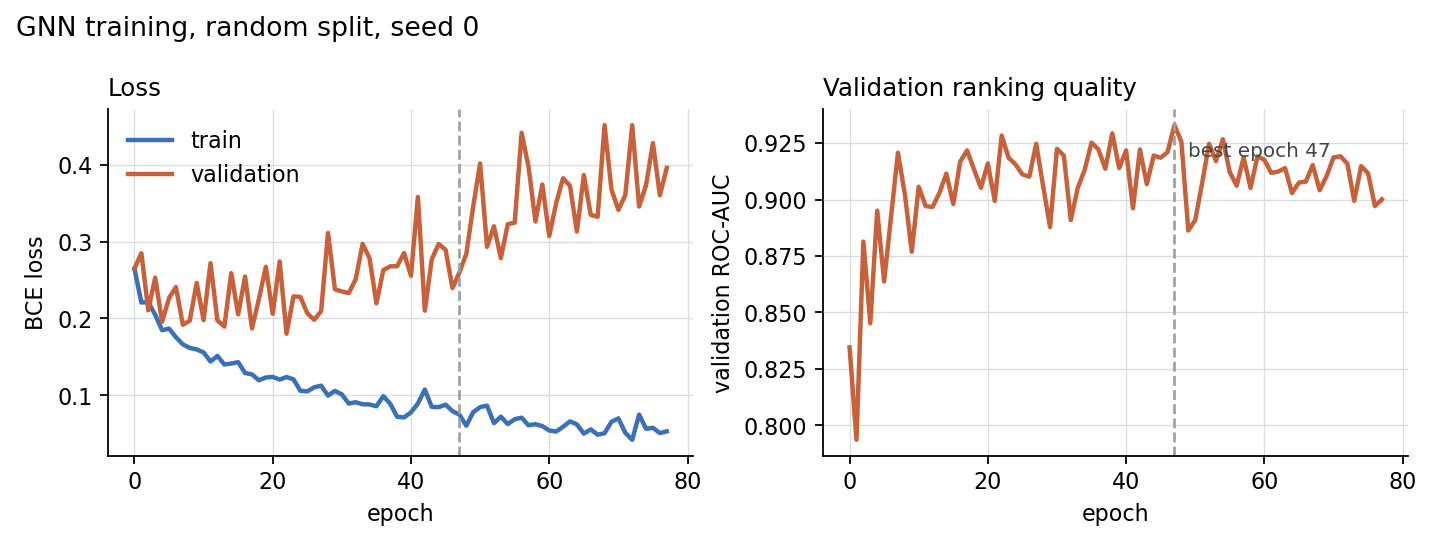

random: validation loss well above training loss at the end: overfitting; best validation ROC-AUC at epoch 47, 30 epochs before the end



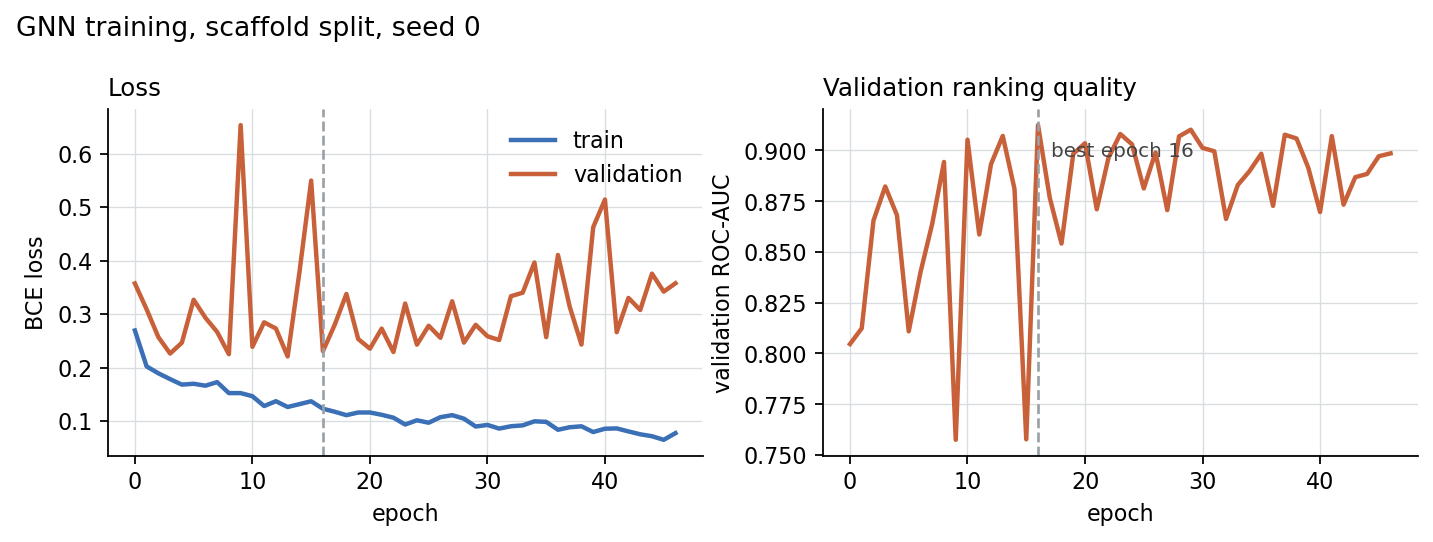

scaffold: validation loss well above training loss at the end: overfitting; best validation ROC-AUC at epoch 16, 30 epochs before the end; validation ROC-AUC is unstable (step sd 0.049)



In [30]:
for nm, runs in gnn_results.items():
    r = runs[0]
    display(Image(str(training_curves(
        r["history"], f"04_training_{nm}.png",
        f"GNN training, {nm} split, seed {r['seed']}"))))
    print(f"{nm}: {r['history'].diagnose()}\n")

### E.4 Seed variation versus the effect of changing the split

In [31]:
METRIC_KEYS = ["roc_auc", "pr_auc", "accuracy", "balanced_accuracy",
               "sensitivity", "specificity", "f1"]

for nm, runs in gnn_results.items():
    print(f"--- {nm} split, mean +/- sd over {len(runs)} seeds")
    for k, vtxt in summarise_runs([r["metrics"] for r in runs]).items():
        print(f"    {k:22s} {vtxt}")
    print()

auc = {nm: np.array([r["metrics"]["roc_auc"] for r in runs])
       for nm, runs in gnn_results.items()}
seed_sd = float(np.mean([a.std(ddof=1) for a in auc.values()]))
split_effect = float(auc["random"].mean() - auc["scaffold"].mean())
print(f"seed noise      (mean sd of ROC-AUC within a split): {seed_sd:.4f}")
print(f"split effect    (random mean - scaffold mean)      : {split_effect:.4f}")
print(f"ratio                                              : {split_effect / seed_sd:.1f}x")
out["seed_vs_split"] = {"seed_sd": seed_sd, "split_effect": split_effect,
                        "ratio": split_effect / seed_sd}
out["gnn_architecture"] = {
    "description": probe.describe(), "n_parameters": probe.n_parameters(),
    "hidden": gnn_cfg.hidden, "layers": gnn_cfg.n_layers, "dropout": gnn_cfg.dropout,
    "pooling": gnn_cfg.pooling, "lr": gnn_cfg.lr, "weight_decay": gnn_cfg.weight_decay,
    "batch_size": gnn_cfg.batch_size, "max_epochs": gnn_cfg.max_epochs,
    "patience": gnn_cfg.patience,
    "loss": "BCEWithLogitsLoss, pos_weight = n_neg/n_pos from train only",
    "optimizer": "Adam", "model_selection": "best validation ROC-AUC, weights restored",
}
out["gnn"] = {
    nm: {"runs": [{"seed": r["seed"], "threshold": r["threshold"],
                   "best_epoch": r["history"].best_epoch,
                   "stopped_epoch": r["history"].stopped_epoch,
                   "diagnosis": r["history"].diagnose(),
                   "metrics": r["metrics"]} for r in runs],
         "summary": summarise_runs([r["metrics"] for r in runs])}
    for nm, runs in gnn_results.items()
}

--- random split, mean +/- sd over 3 seeds
    roc_auc                0.929 +/- 0.011
    pr_auc                 0.978 +/- 0.003
    accuracy               0.876 +/- 0.023
    balanced_accuracy      0.792 +/- 0.031
    sensitivity            0.951 +/- 0.016
    specificity            0.633 +/- 0.047
    f1                     0.922 +/- 0.015

--- scaffold split, mean +/- sd over 3 seeds
    roc_auc                0.791 +/- 0.031
    pr_auc                 0.957 +/- 0.007
    accuracy               0.833 +/- 0.012
    balanced_accuracy      0.597 +/- 0.040
    sensitivity            0.941 +/- 0.024
    specificity            0.254 +/- 0.098
    f1                     0.905 +/- 0.008

seed noise      (mean sd of ROC-AUC within a split): 0.0209
split effect    (random mean - scaffold mean)      : 0.1379
ratio                                              : 6.6x


---
# F. Evaluation

Every number below uses a threshold selected on the corresponding **validation**
subset. Each test set has now been scored exactly once per model per split.

In [32]:
header = (f"{'model':<12}{'split':<10}{'thr':>6}{'ROC-AUC':>18}{'PR-AUC':>18}"
          f"{'accuracy':>18}{'bal-acc':>18}{'sens':>18}{'spec':>18}{'F1':>18}")
print(header); print("-" * len(header))

table_rows = []
for nm in ("random", "scaffold"):
    m = baseline_results[nm]["metrics"]
    row = {"model": "ECFP+LR", "split": nm, "n_runs": 1,
           "threshold": f"{m['threshold']:.3f}"}
    row.update({k: f"{m[k]:.3f}" for k in METRIC_KEYS})
    table_rows.append(row)
    print(f"{'ECFP+LR':<12}{nm:<10}{m['threshold']:>6.2f}"
          + "".join(f"{m[k]:>18.3f}" for k in METRIC_KEYS))
for nm in ("random", "scaffold"):
    s = summarise_runs([r["metrics"] for r in gnn_results[nm]], METRIC_KEYS)
    thr = float(np.mean([r["threshold"] for r in gnn_results[nm]]))
    table_rows.append({"model": "GNN (GINE)", "split": nm,
                       "n_runs": len(gnn_results[nm]), "threshold": f"{thr:.3f}", **s})
    print(f"{'GNN (GINE)':<12}{nm:<10}{thr:>6.2f}"
          + "".join(f"{s[k]:>18}" for k in METRIC_KEYS))

with open(RESULTS / "comparison.csv", "w", newline="") as fh:
    w = csv.DictWriter(fh, fieldnames=list(table_rows[0].keys()))
    w.writeheader(); w.writerows(table_rows)
out["comparison_table"] = table_rows
print(f"\nwritten to {RESULTS / 'comparison.csv'}")

model       split        thr           ROC-AUC            PR-AUC          accuracy           bal-acc              sens              spec                F1
----------------------------------------------------------------------------------------------------------------------------------------------------------
ECFP+LR     random      0.53             0.913             0.969             0.854             0.824             0.880             0.768             0.902
ECFP+LR     scaffold    0.22             0.760             0.946             0.874             0.607             0.996             0.217             0.930
GNN (GINE)  random      0.13   0.929 +/- 0.011   0.978 +/- 0.003   0.876 +/- 0.023   0.792 +/- 0.031   0.951 +/- 0.016   0.633 +/- 0.047   0.922 +/- 0.015
GNN (GINE)  scaffold    0.26   0.791 +/- 0.031   0.957 +/- 0.007   0.833 +/- 0.012   0.597 +/- 0.040   0.941 +/- 0.024   0.254 +/- 0.098   0.905 +/- 0.008

written to /Users/adebayo/Documents/Quant_Learning_and_Projects/bbbp-

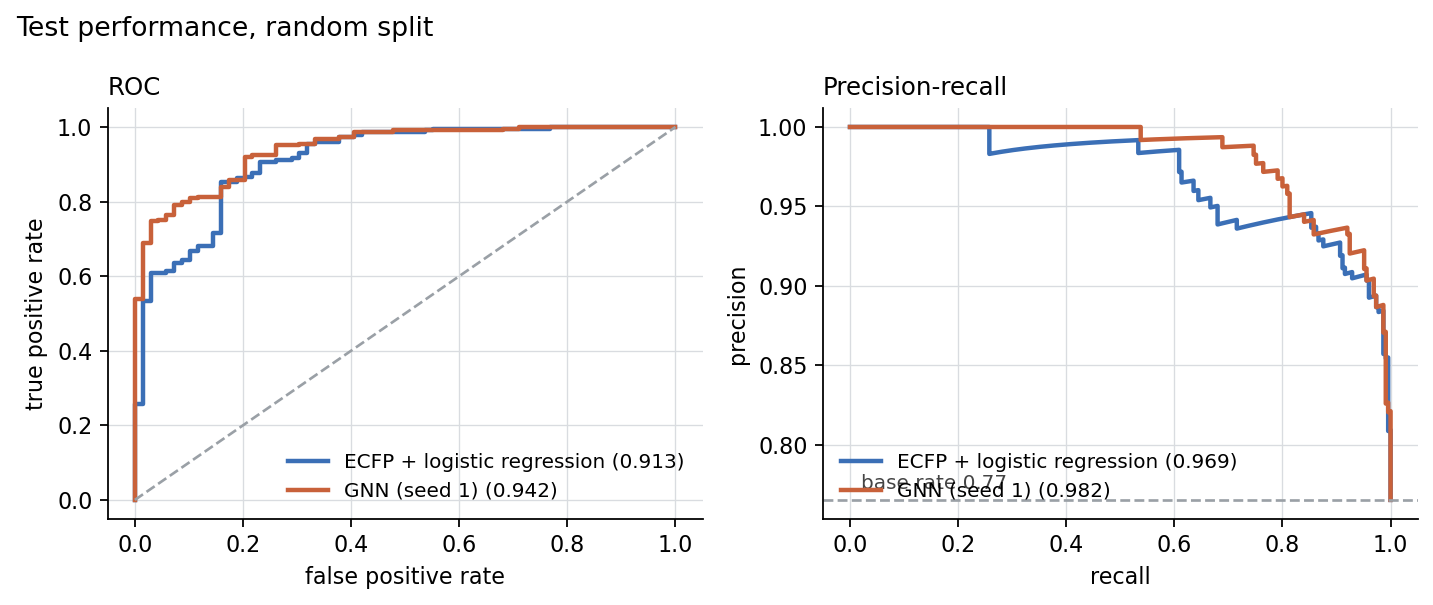

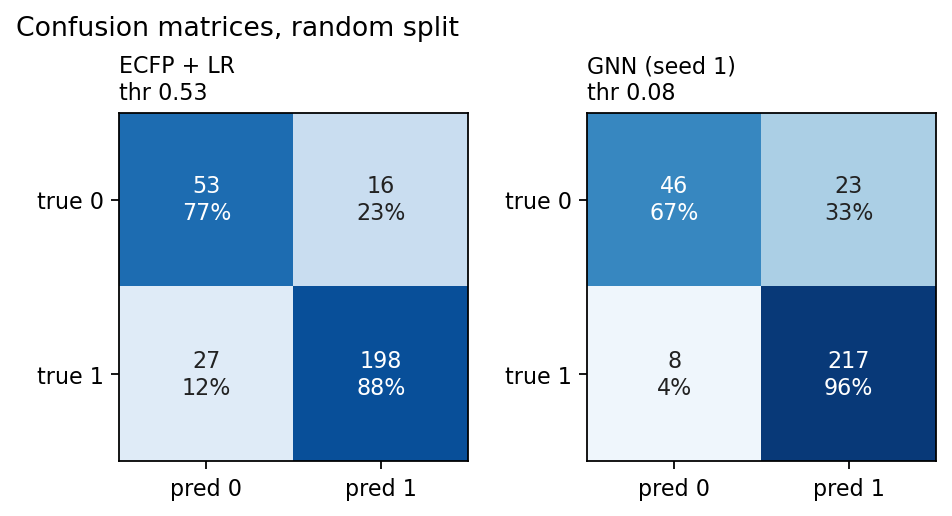

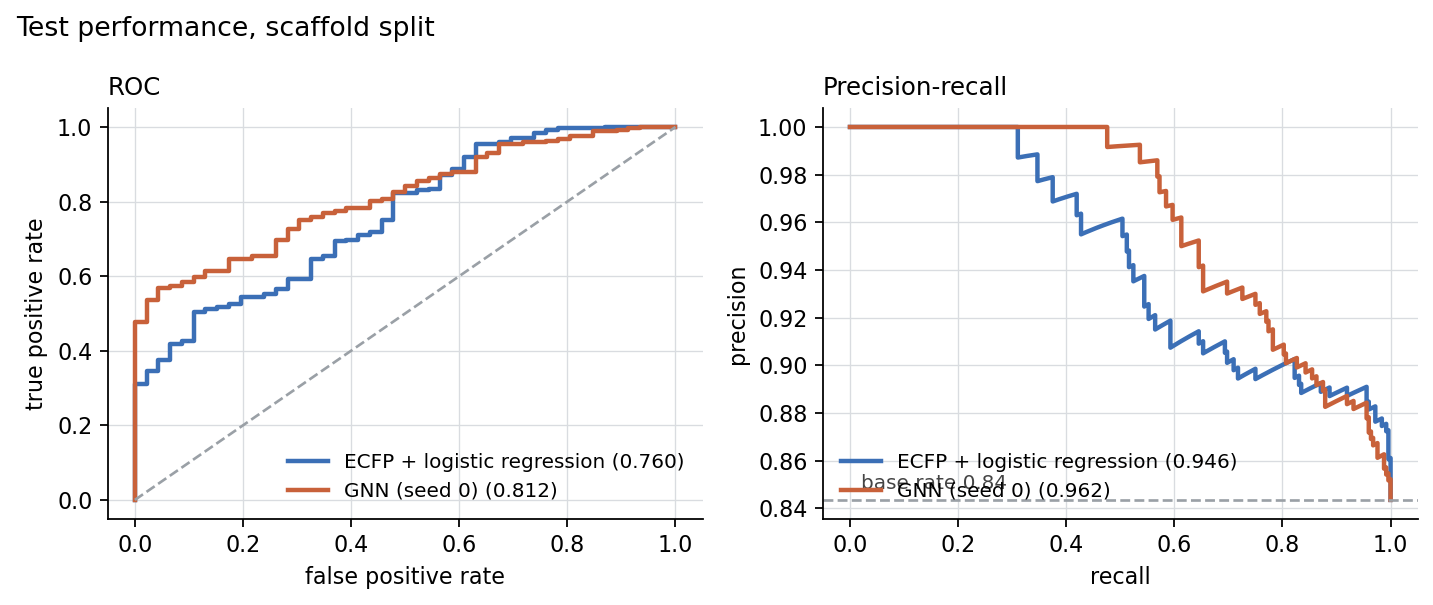

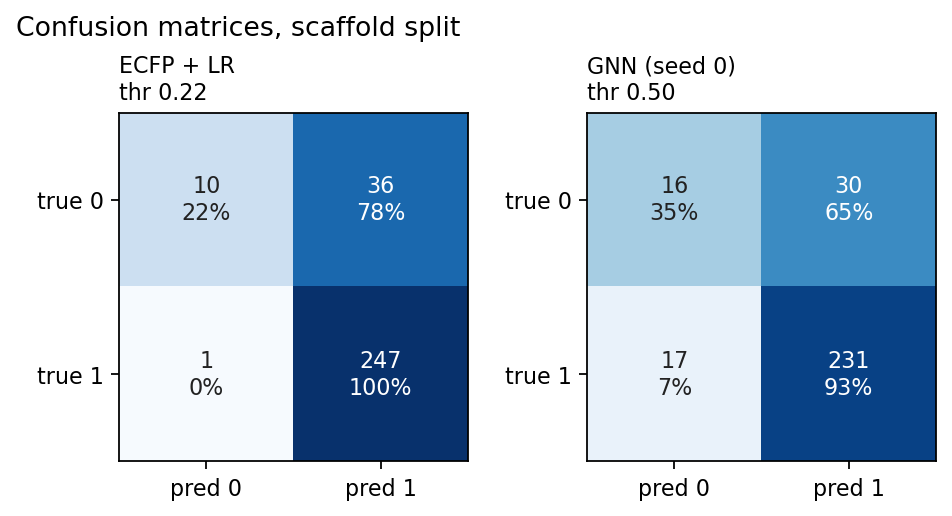

In [33]:
for nm in ("random", "scaffold"):
    best = max(gnn_results[nm], key=lambda r: r["metrics"]["roc_auc"])
    display(Image(str(roc_pr_curves(
        {"ECFP + logistic regression": {"y": baseline_results[nm]["test_y"],
                                        "prob": baseline_results[nm]["test_prob"],
                                        "color_key": "fingerprint"},
         f"GNN (seed {best['seed']})": {"y": best["test_y"], "prob": best["test_prob"],
                                        "color_key": "gnn"}},
        f"05_curves_{nm}.png", f"Test performance, {nm} split"))))
    display(Image(str(confusion_matrices(
        [{"label": "ECFP + LR", "metrics": baseline_results[nm]["metrics"]},
         {"label": f"GNN (seed {best['seed']})", "metrics": best["metrics"]}],
        f"06_confusion_{nm}.png", f"Confusion matrices, {nm} split"))))

### F.1 What the evidence supports

**Baseline versus GNN.** Read the gap against the seed spread, not on its own. The
GNN is ahead on ROC-AUC on both splits, but on the scaffold split the margin is
about the size of one seed standard deviation — so on the split that represents
the question of interest, *this* GNN's advantage over a 2015 fingerprint is not
distinguishable from run-to-run noise. The honest statement is "no demonstrated
advantage at this dataset size", not "the GNN wins" and not "fingerprints win".
A GNN is not entitled to beat a fingerprint; 2,000 molecules is very little data
for 250k parameters.

**Random versus scaffold.** Switching the split costs far more ROC-AUC than
switching the model gains — several times the seed noise. A single random-split
number on BBBP is therefore mostly a report about the split.

**The trap in the accuracy column.** Going to the *harder* split, accuracy and F1
go *up* while specificity collapses. Both models respond to unfamiliar chemistry
by predicting the 76% majority class: sensitivity near 1.0, specificity near zero.
That is the base rate wearing a model's clothes, and it is why the two most
commonly reported numbers in this literature are the two that hide the failure.

**And none of it is biology.** A fingerprint bit co-occurring with a label is a
correlation in a curated table. Nothing here identifies a mechanism of
penetration.

---
# G. Error, similarity and limitations analysis

Every error on the scaffold test set is matched to its most similar training
molecule by Tanimoto similarity over Morgan fingerprints. That separates two
failure modes that call for opposite responses:

- **An error far from anything in training** is an applicability-domain problem.
  The right response is to decline to predict, not to train harder.
- **An error with a close, correctly-labelled neighbour** is a modelling failure,
  an activity cliff, or a label error.

In [34]:
import numpy as np



def error_table(
    test_smiles: list[str],
    y_true: np.ndarray,
    y_prob: np.ndarray,
    threshold: float,
    train_smiles: list[str],
    train_labels: np.ndarray,
    fp_cfg: FingerprintConfig | None = None,
) -> list[dict]:
    """One row per test molecule, with its nearest training neighbour."""
    sims, idx = nearest_training_neighbour(test_smiles, train_smiles, fp_cfg)
    y_true = np.asarray(y_true).astype(int)
    y_pred = (np.asarray(y_prob) >= threshold).astype(int)

    rows = []
    for i, smi in enumerate(test_smiles):
        kind = (
            "TP" if y_true[i] == 1 and y_pred[i] == 1
            else "TN" if y_true[i] == 0 and y_pred[i] == 0
            else "FP" if y_true[i] == 0 and y_pred[i] == 1
            else "FN"
        )
        rows.append(
            {
                "smiles": smi,
                "y_true": int(y_true[i]),
                "y_pred": int(y_pred[i]),
                "prob": float(y_prob[i]),
                "correct": bool(y_true[i] == y_pred[i]),
                "kind": kind,
                "nn_similarity": float(sims[i]),
                "nn_smiles": train_smiles[int(idx[i])],
                "nn_label": int(train_labels[int(idx[i])]),
                "nn_label_agrees": bool(train_labels[int(idx[i])] == y_true[i]),
            }
        )
    return rows


def pick_errors(rows: list[dict], kind: str, n: int = 2) -> list[dict]:
    """The most confident mistakes of a given kind: the ones worth explaining."""
    errs = [r for r in rows if r["kind"] == kind]
    # Most confident = furthest from the decision threshold in the wrong direction.
    errs.sort(key=lambda r: r["prob"], reverse=(kind == "FP"))
    return errs[:n]


def similarity_summary(rows: list[dict]) -> dict:
    """Does similarity to training separate the hits from the misses?"""
    sims = np.array([r["nn_similarity"] for r in rows])
    correct = np.array([r["correct"] for r in rows])

    out = {
        "n": len(rows),
        "accuracy": float(correct.mean()),
        "mean_similarity_correct": float(sims[correct].mean()) if correct.any() else float("nan"),
        "mean_similarity_wrong": float(sims[~correct].mean()) if (~correct).any() else float("nan"),
        "median_similarity": float(np.median(sims)),
    }

    if correct.any() and (~correct).any():
        from scipy.stats import mannwhitneyu

        stat, p = mannwhitneyu(sims[correct], sims[~correct], alternative="greater")
        out["mannwhitney_u"] = float(stat)
        out["p_value_correct_more_similar"] = float(p)

    # Accuracy in the least and most familiar thirds.
    order = np.argsort(sims)
    third = max(1, len(rows) // 3)
    out["accuracy_least_similar_third"] = float(correct[order[:third]].mean())
    out["accuracy_most_similar_third"] = float(correct[order[-third:]].mean())
    out["similarity_cut_least_third"] = float(sims[order[third - 1]])
    out["similarity_cut_most_third"] = float(sims[order[-third]])
    return out

In [35]:
sp = splits["scaffold"]
best = max(gnn_results["scaffold"], key=lambda r: r["metrics"]["roc_auc"])
test_smiles  = [smiles[i] for i in sp.test]
train_smiles = [smiles[i] for i in sp.train]
train_labels = y[sp.train]

rows = error_table(test_smiles, best["test_y"], best["test_prob"], best["threshold"],
                   train_smiles, train_labels, CONFIG.fingerprint)
summary = similarity_summary(rows)
for k, v in summary.items():
    print(f"  {k:38s} {v:.4f}" if isinstance(v, float) else f"  {k:38s} {v}")

with open(RESULTS / "error_rows_scaffold.csv", "w", newline="") as fh:
    w = csv.DictWriter(fh, fieldnames=list(rows[0].keys()))
    w.writeheader(); w.writerows(rows)
out["error_analysis"] = summary

  n                                      294
  accuracy                               0.8401
  mean_similarity_correct                0.3979
  mean_similarity_wrong                  0.3395
  median_similarity                      0.3542
  mannwhitney_u                          7498.5000
  p_value_correct_more_similar           0.0008
  accuracy_least_similar_third           0.7245
  accuracy_most_similar_third            0.9082
  similarity_cut_least_third             0.3077
  similarity_cut_most_third              0.4259


### G.1 Two false positives and two false negatives, each beside its nearest training molecule


FP   predicted p=0.984   true label=0
  molecule: CC(=O)N1CCN(c2ccc(OC[C@H]3CO[C@](Cn4ccnc4)(c4ccc(Cl)cc4Cl)O3)cc2)CC1
  nearest training molecule: Tanimoto 0.267, label 1 (DISAGREES with the true label)
            O=C(COc1ccc(Cl)cc1)N1CCN(Cc2ccc3c(c2)OCO3)CC1

FP   predicted p=0.974   true label=0
  molecule: CC(C)N1CCN(c2ccc(OC[C@H]3CO[C@](Cn4cncn4)(c4ccc(Cl)cc4Cl)O3)cc2)CC1
  nearest training molecule: Tanimoto 0.247, label 1 (DISAGREES with the true label)
            Cl/C(=C\n1cncn1)c1ccc(Cl)cc1Cl

FN   predicted p=0.013   true label=1
  molecule: OCc1ccccc1O[C@@H]1O[C@H](CO)[C@@H](O)[C@H](O)[C@H]1O
  nearest training molecule: Tanimoto 0.333, label 0 (DISAGREES with the true label)
            NCC1OC(OC2C(N)CC(N)C(OC3OC(CO)C(O)C(N)C3O)C2O)C(O)C(O)C1O

FN   predicted p=0.018   true label=1
  molecule: Cc1ncc(CSSCc2cnc(C)c(O)c2CO)c(CO)c1O
  nearest training molecule: Tanimoto 0.512, label 1 (AGREES with the true label)
            CCNCc1c(CSC)cnc(C)c1O


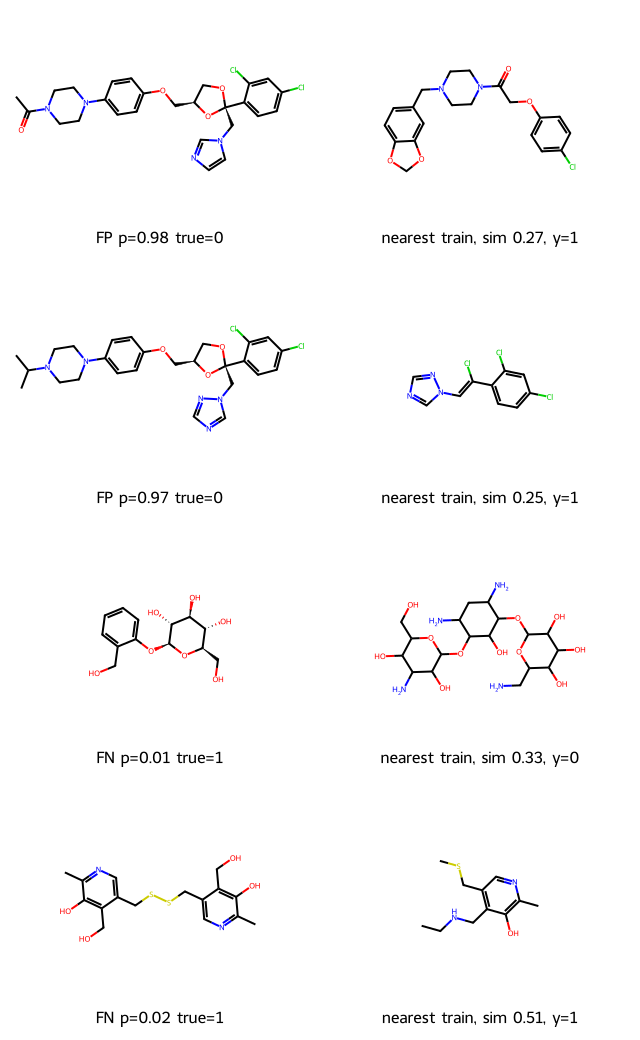

In [36]:
fps = pick_errors(rows, "FP", 2)
fns = pick_errors(rows, "FN", 2)

shown, legends = [], []
for r in fps + fns:
    print(f"\n{r['kind']}   predicted p={r['prob']:.3f}   true label={r['y_true']}")
    print(f"  molecule: {r['smiles']}")
    print(f"  nearest training molecule: Tanimoto {r['nn_similarity']:.3f}, "
          f"label {r['nn_label']} ({'AGREES' if r['nn_label_agrees'] else 'DISAGREES'} "
          f"with the true label)")
    print(f"            {r['nn_smiles']}")
    shown += [r["smiles"], r["nn_smiles"]]
    legends += [f"{r['kind']} p={r['prob']:.2f} true={r['y_true']}",
                f"nearest train, sim {r['nn_similarity']:.2f}, y={r['nn_label']}"]

display(Image(str(molecule_grid(shown, legends, "07_errors_and_neighbours.png",
                                mols_per_row=2))))
out["error_examples"] = fps + fns

**Does similarity explain the error?** Read each pair above on its own terms. A
false positive whose nearest training neighbour is both distant and
oppositely-labelled is the model extrapolating off the end of what it has seen —
the confidence is unearned, and the neighbour tells you so. A false positive with
a *close* neighbour carrying the *same* label it predicted is more interesting: the
model has generalised exactly as intended and still got it wrong, which points at
an activity cliff or at the label.

The aggregate version of that question is the next figure.

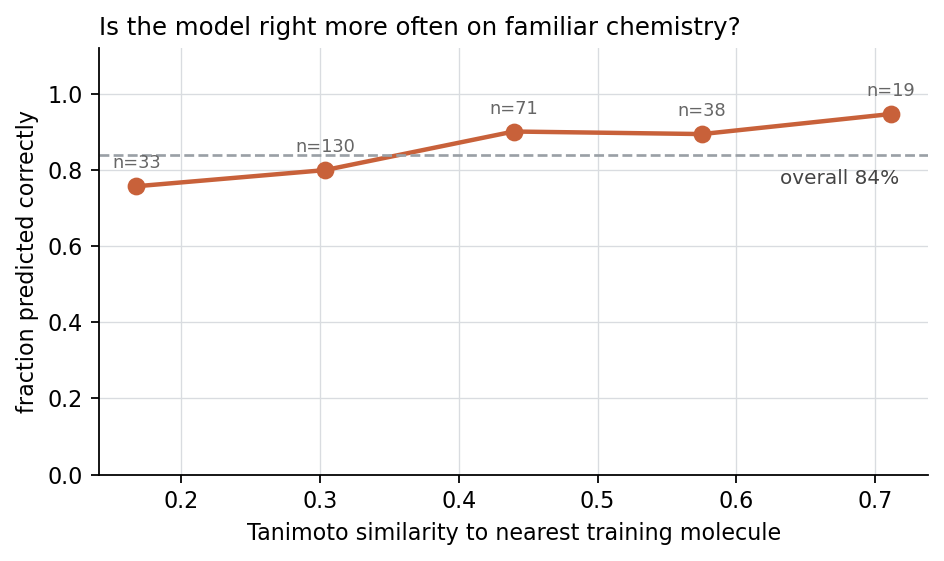

least-similar third correct: 0.724
most-similar third correct : 0.908
mean similarity, correct   : 0.398
mean similarity, wrong     : 0.340
Mann-Whitney U p-value     : 0.0007618


In [37]:
display(Image(str(similarity_vs_correctness(
    [r["nn_similarity"] for r in rows], [r["correct"] for r in rows],
    "08_similarity_vs_accuracy.png",
    "Is the model right more often on familiar chemistry?"))))

print(f"least-similar third correct: {summary['accuracy_least_similar_third']:.3f}")
print(f"most-similar third correct : {summary['accuracy_most_similar_third']:.3f}")
print(f"mean similarity, correct   : {summary['mean_similarity_correct']:.3f}")
print(f"mean similarity, wrong     : {summary['mean_similarity_wrong']:.3f}")
print(f"Mann-Whitney U p-value     : {summary['p_value_correct_more_similar']:.4g}")

The accuracy headline is an average over molecules of very different difficulty.
Error rate tracks distance from the training set, and the difference between the
least- and most-similar thirds is significant. **The model is reliable on familiar
chemistry and close to coin-flipping on unfamiliar chemistry — and nothing in its
output tells you which case you are looking at.** A single probability cannot
distinguish "confident because this is a well-covered series" from "confident
because the extrapolation happened to land somewhere confident".

### G.2 Limitations

1. **The labels are not measurements.** BBBP is a literature compilation across
   assays, species and definitions. The conflicting-label groups removed in § A
   are direct evidence: the same molecule appears with both labels, aspirin among
   them. The achievable ceiling is below 1.0 and this notebook cannot say where.
2. **The dataset is small and narrow.** About 2,000 compounds after cleaning, 76%
   one class, weighted toward marketed drugs — which are themselves a biased
   sample, having already survived development. A 15% test set is ~290 molecules,
   so a two-point difference in any metric is inside the noise.
3. **No external experimental validation.** Every number comes from one dataset
   split three ways. No held-out measurement, no prospective test, no second
   dataset.
4. **Correlation, not causality.** A fingerprint bit co-occurring with a label
   says nothing about mechanism. Nothing here identifies a cause of penetration,
   and a model that reproduces the correlation has not explained it.
5. **Scaffold split is one definition of novelty.** Bemis–Murcko frameworks are a
   crude proxy for "new chemistry": two molecules with different frameworks can be
   near-identical in the properties that govern penetration, and vice versa.
6. **Not a clinical or development tool.** No output here is evidence that a
   compound is safe, effective, or worth synthesising. Using it that way would be
   a misuse of a benchmark experiment.

---
# H. Conclusions

1. **The split moves the result several times more than the model does.** Switching
   from random to scaffold costs far more ROC-AUC than the GNN gains over the
   fingerprint, and on the scaffold split that gain is about one seed standard
   deviation. The reportable finding is not a winner; it is that this comparison
   cannot resolve one at this dataset size.
2. **Accuracy and F1 move the wrong way on the harder split.** They rise while
   specificity collapses, because both models fall back on the 76% base rate.
   Balanced accuracy and specificity are the only columns that show it.
3. **Reliability is not uniform, and it is predictable.** Error rate tracks
   Tanimoto distance to the training set, significantly. That is a property the
   model's own output does not expose — which is exactly where this stops being a
   replication and starts being a question worth working on: a model that knows
   when it does not know.

In [38]:
out["runtime_note"] = "executed top to bottom"
with open(RESULTS / "results_notebook.json", "w") as fh:
    json.dump(out, fh, indent=2, default=lambda o: (
        o.item() if isinstance(o, (np.floating, np.integer))
        else o.tolist() if isinstance(o, np.ndarray)
        else bool(o) if isinstance(o, np.bool_) else str(o)))
print("wrote", RESULTS / "results_notebook.json")
print("figures in", FIGURES)

wrote /Users/adebayo/Documents/Quant_Learning_and_Projects/bbbp-gnn/results/results_notebook.json
figures in /Users/adebayo/Documents/Quant_Learning_and_Projects/bbbp-gnn/results/figures
